# 06 — Traditional ML Anomaly Detection

## 1. Objective

This notebook implements and investigates three traditional machine-learning methods for detecting anomalous behaviour in the SWaT multivariate time-series dataset:

1. **Isolation Forest**
2. **One-Class Support Vector Machine (One-Class SVM)**
3. **Local Outlier Factor (LOF)** using novelty-detection mode.

The objective is to establish how these methods identify observations that differ from patterns learned from normal operating data. Their assumptions, preprocessing requirements, computational costs, anomaly scores, and detection behaviour will be documented and assessed.

## 2. Scope

Each method will be investigated separately using a consistent experimental design wherever technically appropriate. The implementation will preserve chronological data boundaries, fit learned preprocessing on permitted training data, and avoid using attack labels as model features or for selecting thresholds on the final test set.

Particular attention will be given to feature scaling, model hyperparameters, anomaly-score orientation, threshold selection, and computational feasibility.

The results will be documented after each experiment. No method will be considered superior without supporting evidence from the evaluation.

This notebook complements the three baseline methods in Notebook 04 and the LSTM Autoencoder in Notebook 05. Its results will contribute to the subsequent unified evaluation of all nine selected detection methods.

## 3. Methodological Foundations

### 3.1 Learning from Normal Operating Data

The three detectors in this notebook are trained using normal operating data only. Their purpose is to identify observations that differ from the patterns learned during training.

Let the training dataset be

$$
X_{\mathrm{train}} = \{x_1, x_2, \ldots, x_n\}
$$

where each observation $x_i \in \mathbb{R}^{d}$ contains $d$ sensor features.

Each detector learns a representation of normal operating behaviour and assigns an anomaly score to an observation. The score is converted into a binary decision using a threshold:

$$
\hat{y}_i =
\begin{cases}
1, & s(x_i) > \tau, \\
0, & s(x_i) \leq \tau,
\end{cases}
$$

where $s(x_i)$ is the anomaly score, $\tau$ is the selected threshold, $1$ denotes a flagged observation, and $0$ denotes an observation that is not flagged.

The score direction must be verified for each implementation, because some estimators assign lower scores to more anomalous observations and others assign higher scores. Applying a fixed threshold without confirming the direction will produce inverted decisions.

A flagged observation is a model-generated anomaly alert. It is not, by itself, proof of a cyberattack or physical fault.

### 3.2 Isolation Forest

Isolation Forest identifies observations that can be isolated from the rest of the data using randomly selected features and split values.

The underlying principle is that observations that differ substantially from the broader data distribution may require fewer splits to isolate. Their average path lengths in the isolation trees therefore tend to be shorter than those of normal observations.

The method is controlled by parameters such as the number of trees, the number of observations sampled for each tree, and the contamination setting.

The contamination parameter affects the estimator's internal classification boundary. It must not be confused with a threshold calibrated independently using permitted normal calibration data. The contamination setting is a property of the fitted estimator, while the final anomaly threshold is a decision rule applied afterwards to the anomaly scores.

### 3.3 One-Class Support Vector Machine

One-Class SVM learns a decision boundary that describes the training-data distribution.
Observations outside the learned region are identified as potential anomalies. This
notebook uses scikit-learn's `SGDOneClassSVM`, the linear variant of the One-Class SVM
trained by stochastic gradient descent. It has **no kernel or gamma parameter**. Its
behaviour depends on $\nu$, the training sample size, the SGD learning-rate schedule,
and feature scaling.

The $\nu$ parameter provides an upper bound on the fraction of training errors and a
lower bound on the fraction of support vectors under the model formulation. It is not a
guarantee of the detector's false-positive rate on future data.

Because sensor features can have different numerical ranges, the scaling procedure must be examined carefully. Any fitted scaler must be fitted on training data only and applied to later partitions without refitting.

One-Class SVM can also become computationally expensive as the number of training observations increases, with typical complexity scaling between linear and quadratic in the sample size depending on the kernel. The training sample size and runtime must therefore be considered before selecting an implementation.

### 3.4 Local Outlier Factor

Local Outlier Factor identifies observations whose local density differs from that of their neighbours.

The method compares an observation's local reachability density with the corresponding densities of its nearest neighbours. An observation with substantially lower local density than its neighbours receives a higher outlier score.

The neighbourhood size $k$ influences the scale at which local differences are detected. Small neighbourhoods can be sensitive to local fluctuations, while larger neighbourhoods may obscure smaller-scale structures and reduce sensitivity to local anomalies.

Scikit-learn distinguishes between ordinary outlier detection and novelty detection. Ordinary outlier detection (`novelty=False`) assigns scores to the same observations used to fit the model, and cannot be applied to previously unseen data. Novelty detection (`novelty=True`) fits the model on training data and scores new observations as they arrive. Because this project trains detectors on one period and applies them to previously unseen observations, LOF must use `novelty=True`. This allows the fitted model to score new observations without treating the evaluation data as part of the original neighbourhood search.

### 3.5 Chronology, Preprocessing, and Leakage Control

SWaT is a time-series dataset, so chronological order must be preserved. Randomly mixing observations across training and evaluation periods could make the experiment less representative of detecting previously unseen behaviour, and could allow later-period statistics to influence models that are supposed to have been trained on earlier data alone.

All learned preprocessing must be fitted using the permitted training data and then applied to later partitions without refitting.

The models must not receive the `Normal/Attack` label as an input feature. Attack labels must also not be used to optimise thresholds on the final test set.

Threshold calibration and final evaluation follow the project's established evaluation protocol, with the calibration/threshold/validation separation used in earlier notebooks. The implementation details and any method-specific deviations are documented in the relevant sections.

In [40]:
# Universal Path and Environment Setup (Kaggle / Local / Colab)
import os, sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

IS_KAGGLE = (os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None) or (os.name != 'nt' and Path('/kaggle/input').is_dir())
IS_COLAB = ('google.colab' in sys.modules) or (os.name != 'nt' and Path('/content').is_dir() and not IS_KAGGLE)

raw_dir = None
artifact_dir = None

if IS_KAGGLE:
    output_dir = Path('/kaggle/working/swat-artifacts')
    output_dir.mkdir(parents=True, exist_ok=True)
    for p in Path('/kaggle/input').rglob('normal.csv'):
        if p.is_file(): raw_dir = p.parent; break
    for p in Path('/kaggle/input').rglob('scaler.joblib'):
        if p.is_file(): artifact_dir = p.parent; break
    if artifact_dir is None: artifact_dir = output_dir
elif IS_COLAB:
    output_dir = Path('/content/swat-artifacts')
    output_dir.mkdir(parents=True, exist_ok=True)
    for p in Path('/content').rglob('normal.csv'):
        if p.is_file(): raw_dir = p.parent; break
    for p in Path('/content').rglob('scaler.joblib'):
        if p.is_file(): artifact_dir = p.parent; break
    if artifact_dir is None: artifact_dir = output_dir
else:
    cwd = Path.cwd().resolve()
    project_root = next((d for d in [cwd, *cwd.parents] if (d / 'requirements.txt').is_file()), cwd)
    for cand in [project_root / 'data' / 'raw', cwd / 'data' / 'raw', project_root / 'swat-dataset']:
        if (cand / 'normal.csv').is_file(): raw_dir = cand; break
    for cand in [project_root / 'swat-artifacts', project_root / 'models', cwd / 'swat-artifacts', cwd / 'models']:
        if (cand / 'scaler.joblib').is_file(): artifact_dir = cand; break
    output_dir = project_root / 'swat-artifacts'
    output_dir.mkdir(parents=True, exist_ok=True)
    if artifact_dir is None: artifact_dir = output_dir

if raw_dir is None:
    raise FileNotFoundError('Could not locate data directory containing normal.csv.')

DATA_DIR = raw_dir
ARTIFACT_DIR = output_dir
INPUT_ARTIFACT_DIR = artifact_dir

NORMAL_PATH = DATA_DIR / 'normal.csv'
SCALER_PATH = INPUT_ARTIFACT_DIR / 'scaler.joblib' if (INPUT_ARTIFACT_DIR / 'scaler.joblib').is_file() else ARTIFACT_DIR / 'scaler.joblib'
SEQUENCE_PATH = INPUT_ARTIFACT_DIR / 'evaluation_sequences.npz' if (INPUT_ARTIFACT_DIR / 'evaluation_sequences.npz').is_file() else ARTIFACT_DIR / 'evaluation_sequences.npz'
MODEL_PATH = INPUT_ARTIFACT_DIR / 'lstm_autoencoder.pth' if (INPUT_ARTIFACT_DIR / 'lstm_autoencoder.pth').is_file() else ARTIFACT_DIR / 'lstm_autoencoder.pth'

print(f"[ENV] Environment: {'Kaggle' if IS_KAGGLE else ('Colab' if IS_COLAB else 'Local')}")
print(f"  Normal path  : {NORMAL_PATH} (exists: {NORMAL_PATH.is_file()})")
print(f"  Scaler path  : {SCALER_PATH} (exists: {SCALER_PATH.is_file()})")
print(f"  Artifact dir : {ARTIFACT_DIR}")


[ENV] Environment: Kaggle
  Normal path  : /kaggle/input/datasets/<dataset-owner>/swat-artifacts-dataset/swat-dataset/normal.csv (exists: True)
  Scaler path  : /kaggle/input/datasets/<dataset-owner>/swat-artifacts-dataset/swat-artifacts/scaler.joblib (exists: True)
  Artifact dir : /kaggle/working/swat-artifacts


## 4. Data and Input Representation

The traditional machine-learning methods in this notebook will operate on the same 42 sensor features established during the LSTM Autoencoder stage.

The feature set is:

$$
X \in \mathbb{R}^{n \times 42}
$$

where each row represents one chronological observation and each column represents one retained sensor or actuator feature.

The previously established feature-selection and scaling decisions will be reused rather than recomputed independently in this notebook. The saved `MinMaxScaler` contains the 42-feature preprocessing fitted during the earlier normal-data training stage.

The traditional detectors will therefore receive scaled 42-dimensional observations rather than the 30-step sequence tensors used by the LSTM Autoencoder.

This distinction is intentional. The LSTM Autoencoder models temporal sequences explicitly, whereas Isolation Forest, One-Class SVM, and Local Outlier Factor will first be evaluated using individual multivariate observations.

### 4.1 Training Data

Model fitting will use normal operating observations only.

Attack-labelled observations will not be used as training inputs, and attack labels will not be used to select model hyperparameters or anomaly thresholds.

The chronological structure established in the earlier notebooks will be preserved. No random mixing of observations across temporal partitions will be introduced.

### 4.2 Scaling

The existing `MinMaxScaler` will be reused because it was fitted during the established normal-data preprocessing stage.

For a feature $x_j$, Min-Max scaling is represented as

$$
x'_j =
\frac{x_j - x_{j,\min}}
{x_{j,\max} - x_{j,\min}}
$$

where the minimum and maximum values were learned from the permitted normal training data.

The scaler will be applied to later observations without refitting.

This prevents the traditional ML experiments from introducing a second, independently fitted preprocessing scheme.

### 4.3 Method-Specific Considerations

The three methods will use the same 42-dimensional scaled observation representation where technically appropriate.

However, their computational requirements differ substantially:

- **Isolation Forest** can operate on a comparatively large normal training set.
- **One-Class SVM** can become computationally expensive as the number of training observations increases.
- **LOF** can also become computationally expensive because of its nearest-neighbour calculations and will use `novelty=True` for scoring previously unseen observations.

These computational constraints will be considered when defining the model-fitting sample. Any reduction in training observations must preserve chronological order and be explicitly documented rather than introduced implicitly.

The same established evaluation observations will subsequently be used to compare the detectors under a consistent protocol.

## 5. Normal Training Data Preparation

The traditional machine-learning models will be fitted using the previously established normal-data training partition.

The training set contains **221,366 chronological observations** and the same **42 model features** used by the LSTM Autoencoder.

The observations will be extracted from the established eligible normal operating period without changing their chronological order.

The row-eligibility filter matches Notebook 05 Section 5: a row is retained if all 51 sensor columns (the 42 model features plus the 9 excluded constant features) and the timestamp are non-null. This ensures the training rows used here are identical to those used to fit the LSTM Autoencoder, not merely the same count.

The previously fitted `MinMaxScaler` will then transform the 42 features. No new scaler will be fitted in this notebook.

This preparation step does not use `attack.csv`, attack labels, or the validation data.

The resulting matrix has the form

$$
X_{\mathrm{train}} \in \mathbb{R}^{221366 \times 42}.
$$

This matrix is the common input representation for the three traditional detectors. Method-specific computational adjustments, if required, will be documented separately rather than changing the underlying data definition.

In [41]:
import warnings

warnings.filterwarnings("ignore", message=".*Parsing dates.*")


# Established model contract


TRAIN_ROWS = 221_366

EXCLUDED_FEATURES = [
    "P202",
    "P204",
    "P206",
    "P301",
    "P401",
    "P404",
    "P502",
    "P601",
    "P603",
]

scaler = joblib.load(SCALER_PATH)

FEATURE_COLUMNS = list(scaler.feature_names_in_)

if len(FEATURE_COLUMNS) != 42:
    raise ValueError(
        f"Expected 42 model features, found {len(FEATURE_COLUMNS)}."
    )

ALL_SENSOR_COLUMNS = FEATURE_COLUMNS + EXCLUDED_FEATURES

if len(ALL_SENSOR_COLUMNS) != 51:
    raise ValueError(
        f"Expected 51 sensor columns for eligibility, found {len(ALL_SENSOR_COLUMNS)}."
    )

print(f"Normal dataset: {NORMAL_PATH}")
print(f"Training observations required: {TRAIN_ROWS:,}")
print(f"Model features: {len(FEATURE_COLUMNS)}")
print(f"Eligibility filter columns: {len(ALL_SENSOR_COLUMNS)}")


normal = pd.read_csv(NORMAL_PATH, low_memory=False)

normal.columns = normal.columns.str.strip()

missing_sensor_columns = [
    column for column in ALL_SENSOR_COLUMNS
    if column not in normal.columns
]

if missing_sensor_columns:
    raise KeyError(
        f"Expected sensor columns not found in normal.csv: "
        f"{missing_sensor_columns}"
    )


normal["Timestamp"] = pd.to_datetime(
    normal["Timestamp"],
    errors="coerce",
)


# Apply the Notebook 05 Section 5 eligibility filter


sensor_valid = normal[ALL_SENSOR_COLUMNS].notna().all(axis=1)
timestamp_valid = normal["Timestamp"].notna()

eligible_normal = normal.loc[sensor_valid & timestamp_valid].copy()

print(f"\nEligible observations after filter: {len(eligible_normal):,}")


# Take the first TRAIN_ROWS eligible observations, preserving
# chronological order. These are exactly the rows Notebook 05
# used as lstm_train.


if len(eligible_normal) < TRAIN_ROWS:
    raise ValueError(
        f"Expected at least {TRAIN_ROWS:,} eligible training observations, "
        f"but only {len(eligible_normal):,} were found."
    )

training_df = eligible_normal.iloc[:TRAIN_ROWS][
    ["Timestamp", *FEATURE_COLUMNS]
].copy()


if not training_df["Timestamp"].is_monotonic_increasing:
    raise ValueError(
        "Training observations are not in chronological order."
    )


# Extract the raw feature matrix, and scale it by passing the DataFrame
# so the scaler's stored feature names are used and the sklearn
# feature-names warning is not raised.


X_train_raw_df = training_df[FEATURE_COLUMNS]

X_train_raw = X_train_raw_df.to_numpy(dtype=np.float32)

X_train = scaler.transform(X_train_raw_df).astype(np.float32)


# Final validation


if X_train.shape != (TRAIN_ROWS, 42):
    raise ValueError(
        f"Unexpected training matrix shape: {X_train.shape}"
    )

if not np.isfinite(X_train).all():
    raise ValueError("Scaled training matrix contains NaN or infinity.")

print("\n" + "=" * 60)
print("TRAINING DATA READY")
print("=" * 60)

print(f"Raw training shape:    {X_train_raw.shape}")
print(f"Scaled training shape: {X_train.shape}")
print(f"First timestamp:       {training_df['Timestamp'].iloc[0]}")
print(f"Last timestamp:        {training_df['Timestamp'].iloc[-1]}")
print(f"NaN in scaled data:    {np.isnan(X_train).any()}")
print(f"Inf in scaled data:    {np.isinf(X_train).any()}")

Normal dataset: /kaggle/input/datasets/<dataset-owner>/swat-artifacts-dataset/swat-dataset/normal.csv
Training observations required: 221,366
Model features: 42
Eligibility filter columns: 51

Eligible observations after filter: 395,298

TRAINING DATA READY
Raw training shape:    (221366, 42)
Scaled training shape: (221366, 42)
First timestamp:       2015-12-28 10:00:00
Last timestamp:        2015-12-31 12:43:42
NaN in scaled data:    False
Inf in scaled data:    False


## 6. Isolation Forest

### 6.1 Method

Isolation Forest is an unsupervised anomaly-detection method based on the principle that unusual observations are easier to isolate than observations belonging to dense regions of the normal data distribution.

The algorithm constructs an ensemble of randomized isolation trees. Each tree recursively partitions the feature space using randomly selected features and split values.

An observation that requires fewer splits to become isolated has a shorter average path length and is considered more anomalous.

The method is therefore suited to identifying observations that differ from the learned multivariate structure of normal operating data without requiring attack labels during training.

### 6.2 Training Configuration

The model is fitted on the **221,366 normal training observations** established in Section 5, using the same **42 scaled features** from the MinMaxScaler fitted in Notebook 05. These are the same rows that Notebook 05 used as `lstm_train` — same timestamps, same feature order, same scaling. No row differs between the LSTM training set and the Isolation Forest training set.

The following parameters are used:

| Parameter | Value | Rationale |
|:--|:--|:--|
| `n_estimators` | 200 | Standard ensemble size; 100 is the sklearn default, 200 is used here for a slightly more stable path-length estimate |
| `max_samples` | `"auto"` | sklearn resolves this to `min(256, n_samples)`; here it resolves to 256 rows per tree |
| `contamination` | `"auto"` | Score output remains pure; the internal classification boundary is not used as the decision threshold |
| `random_state` | 42 | Matches the project-wide seed established in Notebook 05 Section 4 |
| `n_jobs` | -1 | Uses all available CPU cores; no effect on results, only runtime |

A note on max_samples: the "auto" setting fits each tree on a random min(256, n_samples) subsample. At 221,366 training observations, each tree uses 256 rows; the full dataset determines the sampling distribution but not the individual tree fits.

The contamination setting is not interpreted as an observed attack rate or as an independently established false-positive rate. Because `contamination="auto"` is used, the estimator's internal classification boundary (`offset_`) does not affect the anomaly scores. The anomaly threshold used for final decisions is calibrated **externally** on held-out normal calibration data, using the same 99th-percentile procedure applied in Notebook 05 Section 17.

### 6.3 Score Orientation

Scikit-learn's `IsolationForest` exposes three related outputs:

- `score_samples(X)` — the raw anomaly score; **higher values mean more normal**; the anomalous end of the scale is negative and unbounded below.
- `decision_function(X)` — `score_samples(X) - offset_`; positive means normal, negative means anomalous (sign depends on the internal threshold).
- `predict(X)` — binary +1 (normal) or −1 (anomalous), based on `decision_function`.

Because the project's convention (established in Notebook 05 Section 3.1) is that **larger scores represent greater anomaly indication**, this notebook computes the final anomaly score as:

$$
s(x_i) = -\,\texttt{score\_samples}(x_i)
$$

so that larger $s(x_i)$ indicates more anomalous behaviour. This is the score that will be calibrated against the threshold-calibration observations and thresholded for the final decision.

The score distribution on training observations, threshold-calibration observations, and validation observations is inspected before any threshold is selected.

### 6.4 Evaluation Data

Isolation Forest produces anomaly scores for three observation sets, chosen to match Notebook 05's chronological structure:

| Subset | Observations | Source | Purpose |
|:--|--:|:--|:--|
| Training | 221,366 | First 70% of the 316,238 calibration observations | Model fitting |
| Threshold calibration | 47,437 | Last 15% of the 316,238 calibration observations | Threshold calibration at the 99th percentile |
| Validation | 79,060 | 20% validation portion of `normal.csv` | Out-of-sample flag-rate measurement |

The 47,435-row "monitoring" subset that Notebook 05 used for LSTM early stopping is not used by Isolation Forest, because Isolation Forest has no gradient-based training loop and no early stopping. This is the only divergence from Notebook 05's split — every other row is identical.

The threshold-calibration flag rate should be approximately 1% by construction (since the threshold is defined as the 99th percentile of the calibration scores). The validation flag rate is measured against that fixed threshold, exactly as in Notebook 05 Section 18.

### 6.5 Limitations

Isolation Forest does not explicitly model temporal dependence between consecutive observations. Each 42-dimensional observation is evaluated independently from its feature-space representation.

Consequently, an anomaly score from Isolation Forest represents deviation of an observation from the learned normal distribution rather than a direct model of temporal sequence behaviour. This is the same limitation the LSTM Autoencoder does *not* have: the LSTM Autoencoder observes 30-step windows, whereas Isolation Forest observes single observations.

The `max_samples=auto` default also means each tree sees only a random 256-row subsample. This is intentional in Isolation Forest and generally robust, but it does limit how precisely the model can characterise the tails of the 221,366-row training distribution.

Computational cost and score behaviour on this dataset will be documented from the actual experiment output rather than predicted in advance.

In [42]:
from sklearn.ensemble import IsolationForest
from time import perf_counter

# Reproducible Isolation Forest configuration
IF_RANDOM_STATE = 42
IF_N_ESTIMATORS = 200
IF_MAX_SAMPLES = "auto"

isolation_forest = IsolationForest(
    n_estimators=IF_N_ESTIMATORS,
    max_samples=IF_MAX_SAMPLES,
    random_state=IF_RANDOM_STATE,
    n_jobs=-1,
    contamination="auto",
)

print("=" * 60)
print("ISOLATION FOREST — TRAINING")
print("=" * 60)

print(f"Training observations: {X_train.shape[0]:,}")
print(f"Features: {X_train.shape[1]}")
print(f"Number of trees: {IF_N_ESTIMATORS}")
print(f"Maximum samples per tree: {IF_MAX_SAMPLES}")
print(f"Contamination setting: auto")
print(f"Random state: {IF_RANDOM_STATE}")

start_time = perf_counter()

isolation_forest.fit(X_train)

training_seconds = perf_counter() - start_time

print("\nTraining completed successfully.")
print(f"Fitted trees: {len(isolation_forest.estimators_)}")
print(f"Training time: {training_seconds:.2f} seconds")

ISOLATION FOREST — TRAINING
Training observations: 221,366
Features: 42
Number of trees: 200
Maximum samples per tree: auto
Contamination setting: auto
Random state: 42

Training completed successfully.
Fitted trees: 200
Training time: 0.76 seconds


## 7. Isolation Forest Score Verification

Isolation Forest provides two relevant scoring methods:

- `score_samples(X)` returns lower values for observations that are more anomalous.
- `decision_function(X)` returns values relative to the model's learned decision boundary; negative values indicate observations classified as outliers under that boundary.

For consistency across the project, anomaly scores will be represented so that **higher values indicate greater anomaly severity**. The raw scores will be inspected before any conversion or threshold selection.

This step verifies the model's scoring behaviour without using attack data or changing the fitted model.

In [43]:
import numpy as np

# Inspect the fitted model's anomaly-score direction.
# Use existing training observations; do not reload or refit the model.

if_raw_scores = isolation_forest.score_samples(X_train)

if not np.isfinite(if_raw_scores).all():
    raise ValueError("Isolation Forest produced non-finite training scores.")

if_anomaly_scores = -if_raw_scores

print("=" * 60)
print("ISOLATION FOREST — SCORE VERIFICATION")
print("=" * 60)

print(f"Observations scored: {len(if_raw_scores):,}")
print(f"Raw score minimum: {if_raw_scores.min():.8f}")
print(f"Raw score maximum: {if_raw_scores.max():.8f}")
print(f"Raw score mean:    {if_raw_scores.mean():.8f}")
print(f"Raw score median:  {np.median(if_raw_scores):.8f}")

print("\nConverted anomaly scores (higher = more anomalous):")
print(f"Minimum: {if_anomaly_scores.min():.8f}")
print(f"Maximum: {if_anomaly_scores.max():.8f}")
print(f"Mean:    {if_anomaly_scores.mean():.8f}")
print(f"Median:  {np.median(if_anomaly_scores):.8f}")

print("\nAll scores are finite:", np.isfinite(if_anomaly_scores).all())

ISOLATION FOREST — SCORE VERIFICATION
Observations scored: 221,366
Raw score minimum: -0.70388980
Raw score maximum: -0.36436952
Raw score mean:    -0.44267945
Raw score median:  -0.42324044

Converted anomaly scores (higher = more anomalous):
Minimum: 0.36436952
Maximum: 0.70388980
Mean:    0.44267945
Median:  0.42324044

All scores are finite: True


### 7.1 Findings

The fitted Isolation Forest produced finite scores for all 221,366 training observations. The raw `score_samples` values ranged from −0.70388980 to −0.36436952, with a mean of −0.44267945 and a median of −0.42324044.

Negating these values produces anomaly scores ranging from 0.36436952 to 0.70388980. This transformation establishes a consistent score direction in which higher values indicate greater anomaly severity.

All training scores were finite. This check confirms that the scoring transformation is numerically valid; it does not establish detection performance on unseen observations.

In [44]:

# Established chronological partition sizes
MONITOR_ROWS = 47_435
THRESHOLD_ROWS = 47_437
VALIDATION_ROWS = 79_060

# Confirm the expected eligible-normal dataset size
expected_rows = TRAIN_ROWS + MONITOR_ROWS + THRESHOLD_ROWS + VALIDATION_ROWS

if len(eligible_normal) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows:,} eligible observations, "
        f"but found {len(eligible_normal):,}."
    )

# Extract the threshold-calibration partition
threshold_start = TRAIN_ROWS + MONITOR_ROWS
threshold_end = threshold_start + THRESHOLD_ROWS

threshold_df = eligible_normal.iloc[threshold_start:threshold_end].copy()

# Extract the chronological validation partition
validation_df = eligible_normal.iloc[threshold_end:].copy()

# Apply the existing scaler to the established 42 features
X_threshold = scaler.transform(
    threshold_df[FEATURE_COLUMNS]
).astype(np.float32)

X_validation = scaler.transform(
    validation_df[FEATURE_COLUMNS]
).astype(np.float32)

# Verify shapes, finiteness, and chronological order
assert X_threshold.shape == (THRESHOLD_ROWS, len(FEATURE_COLUMNS))
assert X_validation.shape == (VALIDATION_ROWS, len(FEATURE_COLUMNS))
assert np.isfinite(X_threshold).all()
assert np.isfinite(X_validation).all()

assert threshold_df["Timestamp"].is_monotonic_increasing
assert validation_df["Timestamp"].is_monotonic_increasing
assert threshold_df["Timestamp"].iloc[-1] < validation_df["Timestamp"].iloc[0]

print("=" * 60)
print("ISOLATION FOREST — CALIBRATION AND VALIDATION DATA")
print("=" * 60)

print(f"Threshold observations:  {len(X_threshold):,}")
print(f"Validation observations: {len(X_validation):,}")
print(f"Number of features:      {len(FEATURE_COLUMNS)}")

print(
    "Threshold period:        "
    f"{threshold_df['Timestamp'].iloc[0]} to "
    f"{threshold_df['Timestamp'].iloc[-1]}"
)
print(
    "Validation period:       "
    f"{validation_df['Timestamp'].iloc[0]} to "
    f"{validation_df['Timestamp'].iloc[-1]}"
)

print("All scaled values finite: True")
print("Chronological separation verified: True")

ISOLATION FOREST — CALIBRATION AND VALIDATION DATA
Threshold observations:  47,437
Validation observations: 79,060
Number of features:      42
Threshold period:        2016-01-01 02:23:18 to 2016-01-01 15:51:19
Validation period:       2016-01-01 15:51:20 to 2016-01-02 14:59:59
All scaled values finite: True
Chronological separation verified: True


In [45]:
# Generate anomaly scores.
# Negation ensures that higher values indicate greater anomaly severity.

if_threshold_scores = -isolation_forest.score_samples(X_threshold)
if_validation_scores = -isolation_forest.score_samples(X_validation)

# Verify score dimensions and numerical validity
assert if_threshold_scores.shape == (len(X_threshold),)
assert if_validation_scores.shape == (len(X_validation),)
assert np.isfinite(if_threshold_scores).all()
assert np.isfinite(if_validation_scores).all()

print("=" * 60)
print("ISOLATION FOREST — CALIBRATION AND VALIDATION SCORES")
print("=" * 60)

print("\nThreshold-calibration scores")
print(f"Observations: {len(if_threshold_scores):,}")
print(f"Minimum:      {if_threshold_scores.min():.8f}")
print(f"Maximum:      {if_threshold_scores.max():.8f}")
print(f"Mean:         {if_threshold_scores.mean():.8f}")
print(f"Median:       {np.median(if_threshold_scores):.8f}")

print("\nValidation scores")
print(f"Observations: {len(if_validation_scores):,}")
print(f"Minimum:      {if_validation_scores.min():.8f}")
print(f"Maximum:      {if_validation_scores.max():.8f}")
print(f"Mean:         {if_validation_scores.mean():.8f}")
print(f"Median:       {np.median(if_validation_scores):.8f}")

print("\nAll calibration scores finite:",
      np.isfinite(if_threshold_scores).all())
print("All validation scores finite:",
      np.isfinite(if_validation_scores).all())

ISOLATION FOREST — CALIBRATION AND VALIDATION SCORES

Threshold-calibration scores
Observations: 47,437
Minimum:      0.43779413
Maximum:      0.67673471
Mean:         0.50362866
Median:       0.49742030

Validation scores
Observations: 79,060
Minimum:      0.44230887
Maximum:      0.67931416
Mean:         0.51358185
Median:       0.50709502

All calibration scores finite: True
All validation scores finite: True


### 7.2 Calibration and Validation Score Findings

Isolation Forest generated anomaly scores for 47,437 threshold-calibration observations and 79,060 validation observations. All scores were finite.

The calibration scores ranged from 0.43779413 to 0.67673471, with a mean of 0.50362866 and a median of 0.49742030. The validation scores ranged from 0.44230887 to 0.67931416, with a mean of 0.51358185 and a median of 0.50709502.

Both the mean and median scores were higher in the validation partition. This indicates a difference in the score distributions between the two chronological partitions. The difference alone does not establish the presence or cause of anomalous behaviour.

The calibration and validation scores have been generated separately and will be retained for the unified evaluation in Notebook 08. No final anomaly threshold has been selected in this notebook.

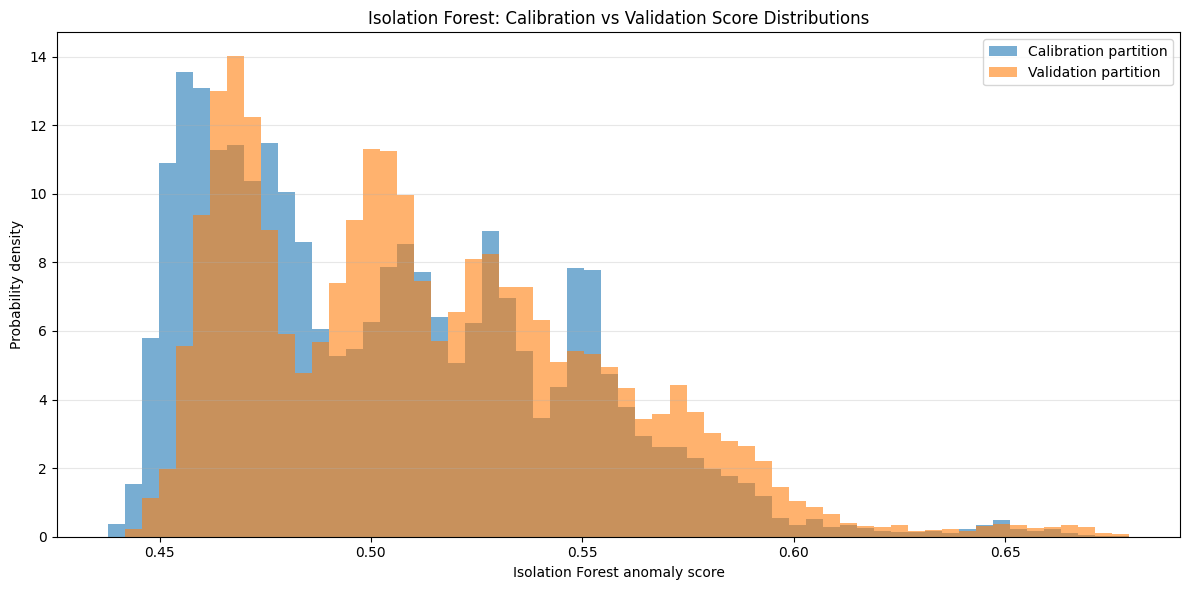

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Verify that the existing score arrays are available and valid.
assert len(if_threshold_scores) == len(threshold_df), (
    "Calibration score count does not match calibration observations."
)
assert len(if_validation_scores) == len(validation_df), (
    "Validation score count does not match validation observations."
)

assert np.isfinite(if_threshold_scores).all(), (
    "Calibration scores contain non-finite values."
)
assert np.isfinite(if_validation_scores).all(), (
    "Validation scores contain non-finite values."
)

# Use common bin edges so the distributions can be compared fairly.
all_scores = np.concatenate([
    if_threshold_scores,
    if_validation_scores
])

bin_edges = np.histogram_bin_edges(all_scores, bins=60)

plt.figure(figsize=(12, 6))

plt.hist(
    if_threshold_scores,
    bins=bin_edges,
    alpha=0.6,
    label="Calibration partition",
    density=True
)

plt.hist(
    if_validation_scores,
    bins=bin_edges,
    alpha=0.6,
    label="Validation partition",
    density=True
)

plt.xlabel("Isolation Forest anomaly score")
plt.ylabel("Probability density")
plt.title("Isolation Forest: Calibration vs Validation Score Distributions")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

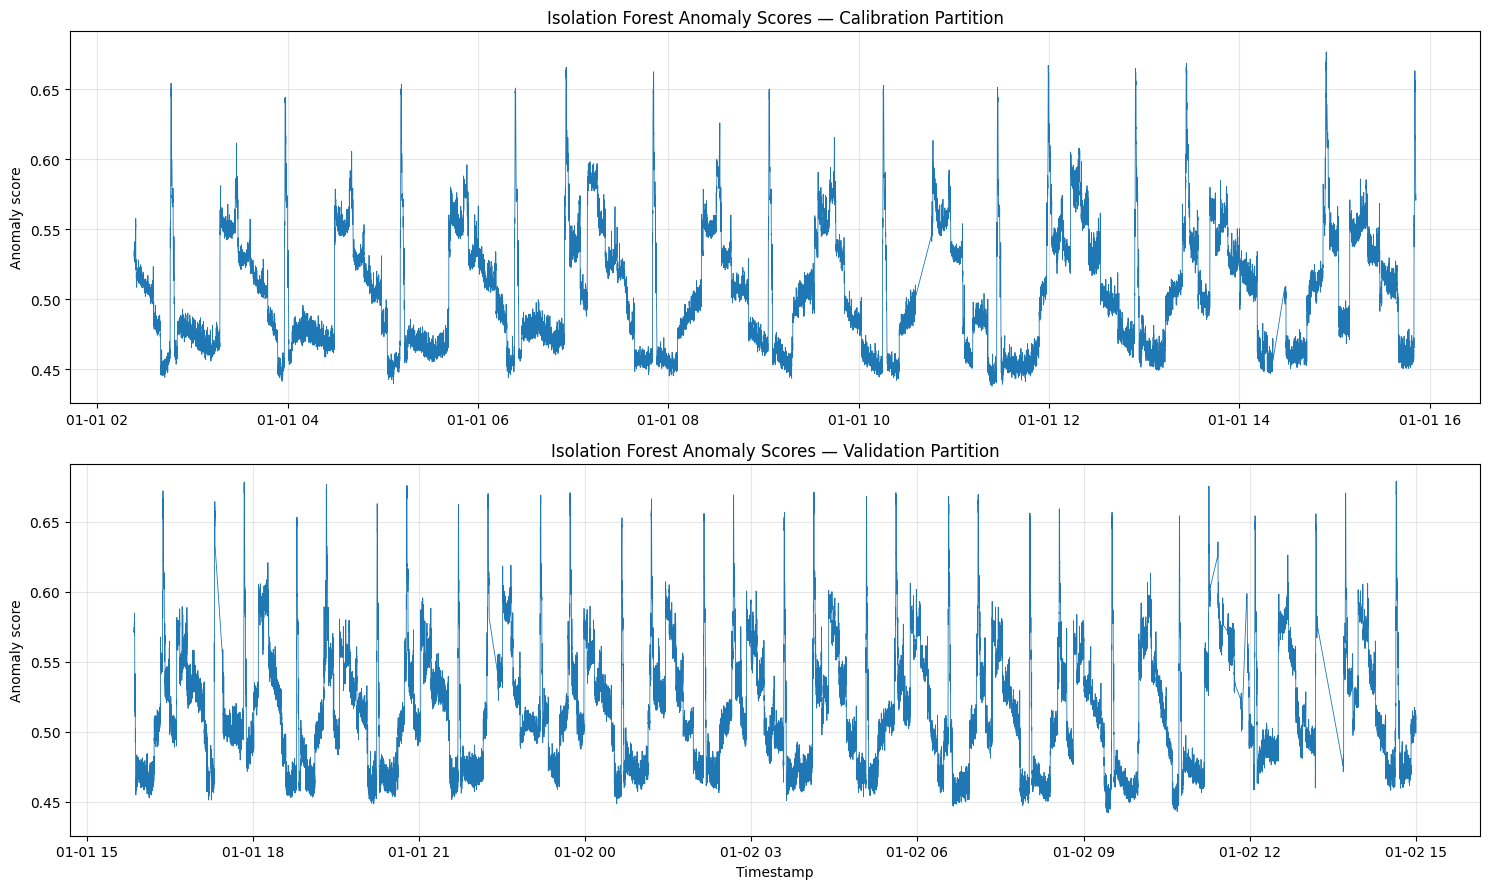

In [47]:
# Verify that the timestamps and scores align.
assert len(threshold_df["Timestamp"]) == len(if_threshold_scores)
assert len(validation_df["Timestamp"]) == len(if_validation_scores)

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 9),
    sharey=True
)

axes[0].plot(
    threshold_df["Timestamp"],
    if_threshold_scores,
    linewidth=0.6
)

axes[0].set_title("Isolation Forest Anomaly Scores — Calibration Partition")
axes[0].set_ylabel("Anomaly score")
axes[0].grid(alpha=0.3)

axes[1].plot(
    validation_df["Timestamp"],
    if_validation_scores,
    linewidth=0.6
)

axes[1].set_title("Isolation Forest Anomaly Scores — Validation Partition")
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Anomaly score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7.3 Visual Analysis of Anomaly Scores

#### Objective

Compare the Isolation Forest anomaly-score distributions and temporal behaviour across the calibration and validation partitions to assess their similarities and identify patterns requiring further investigation.

#### Score Distribution Analysis

The calibration and validation score distributions overlap substantially. Both exhibit a multimodal structure, with visible concentrations around 0.46, 0.51, and 0.55, together with a thinner upper tail.

The mean anomaly score increases from 0.503629 in calibration to 0.513582 in validation, while the median increases from 0.497420 to 0.507095. The maximum scores are similar at 0.676735 and 0.679314, respectively.

These observations indicate broadly similar score distributions, with slightly higher central scores in validation. However, distributional similarity alone does not establish generalization performance or confirm that elevated scores represent anomalies.

#### Temporal Score Behaviour

The temporal plots show variation in anomaly scores across both partitions, including occasional elevated values reaching approximately 0.65–0.68.

These observations identify periods that may warrant further examination. However, the plots alone do not establish periodicity, confirm anomalous events, or identify the operational causes of elevated scores.

#### Interpretation and Limitations

The visual analysis provides an initial assessment of Isolation Forest score behaviour on normal-operation calibration and validation data. The overlapping distributions and similar maximum scores suggest that the score ranges are broadly comparable across the two partitions.

Nevertheless, the model's detection performance remains undetermined. The final anomaly threshold has not been selected, and no attack-labelled evaluation has been performed in this notebook section. Visual patterns must therefore be treated as descriptive evidence rather than confirmed anomaly detections.

#### Conclusion

Isolation Forest produces finite anomaly scores with broadly overlapping calibration and validation distributions. Both partitions exhibit temporal variation and occasional elevated scores. These findings support proceeding to the project's unified threshold-selection and evaluation stage, where anomaly classifications and detection performance will be assessed using the predefined methodology.

## 8. One-Class SVM

#### 8.1 Implementation and Computational Strategy

The exact RBF-kernel One-Class SVM can become computationally expensive for large training sets. To retain all 221,366 normal training observations without incurring the full cost of the exact kernel method, this experiment will assess the scalable `SGDOneClassSVM` implementation provided by scikit-learn.

SGDOneClassSVM is the linear One-Class SVM trained by stochastic gradient descent. It operates directly in the 42-dimensional scaled feature space. Its principal tunable parameters are `nu`, `max_iter`, `tol`, `learning_rate`, and
`random_state` (among others such as `fit_intercept`, `eta0`, `power_t`, `average`,
`warm_start`, and `shuffle`). It has no kernel or gamma parameter.

The experiment will reuse the established 42-feature representation and the scaler fitted during the normal-data training stage. All training observations will be retained, and attack-labelled observations will not be used for fitting.

The optimization configuration and convergence checks will be documented before the fitted model is accepted. Final anomaly-threshold selection and comparative evaluation will be performed in Notebook 08.

In [48]:
import inspect
import sklearn
from sklearn.linear_model import SGDOneClassSVM

print("=" * 60)
print("ONE-CLASS SVM — IMPLEMENTATION COMPATIBILITY")
print("=" * 60)

print("scikit-learn version:", sklearn.__version__)
print("Estimator:", SGDOneClassSVM.__name__)
print("Supported parameters:")
print(inspect.signature(SGDOneClassSVM))

print("\nTraining observations:", f"{X_train.shape[0]:,}")
print("Features:", X_train.shape[1])
print("Training data finite:", bool(np.isfinite(X_train).all()))

ONE-CLASS SVM — IMPLEMENTATION COMPATIBILITY
scikit-learn version: 1.6.1
Estimator: SGDOneClassSVM
Supported parameters:
(nu=0.5, fit_intercept=True, max_iter=1000, tol=0.001, shuffle=True, verbose=0, random_state=None, learning_rate='optimal', eta0=0.0, power_t=0.5, warm_start=False, average=False)

Training observations: 221,366
Features: 42
Training data finite: True


#### 8.2 Methodology and Configuration

The experiment uses `SGDOneClassSVM`, a scalable implementation of the One-Class SVM objective that uses stochastic gradient descent. It is selected to make fitting on the full normal training partition computationally feasible.

SGDOneClassSVM learns a linear decision boundary in the 42-dimensional scaled feature space.

The model will use all 221,366 observations in the established normal training partition and the same 42 scaled features used by the other detectors. The existing scaler will be reused without refitting.

The initial configuration sets `nu=0.01`, `tol=None`, and `random_state=42`. Disabling tolerance-based stopping makes `max_iter` the explicit upper limit on training iterations; it does not establish that a particular iteration count is sufficient.

The iteration limit and optimization behaviour will be examined before the model is accepted. No attack-labelled observations will be used for fitting or threshold selection. Threshold calibration and comparative evaluation will be conducted in Notebook 08.

In [49]:
from sklearn.linear_model import SGDOneClassSVM
from time import perf_counter
import numpy as np

# Full-data feasibility run
OCSVM_NU = 0.01
OCSVM_RANDOM_STATE = 42
OCSVM_PROBE_ITERATIONS = 20

ocsvm_probe = SGDOneClassSVM(
    nu=OCSVM_NU,
    tol=None,
    max_iter=OCSVM_PROBE_ITERATIONS,
    random_state=OCSVM_RANDOM_STATE,
    verbose=1,
)

print("=" * 60)
print("SGD ONE-CLASS SVM — FULL-DATA FEASIBILITY RUN")
print("=" * 60)

print(f"Training observations: {X_train.shape[0]:,}")
print(f"Features: {X_train.shape[1]}")
print(f"nu: {OCSVM_NU}")
print(f"Maximum iterations: {OCSVM_PROBE_ITERATIONS}")
print("Tolerance-based stopping: disabled")
print(f"Random state: {OCSVM_RANDOM_STATE}")

start_time = perf_counter()
ocsvm_probe.fit(X_train)
probe_seconds = perf_counter() - start_time

probe_scores = ocsvm_probe.score_samples(X_train)

if not np.isfinite(probe_scores).all():
    raise ValueError("The feasibility run produced non-finite scores.")

print("\nFeasibility run completed.")
print(f"Iterations performed: {ocsvm_probe.n_iter_}")
print(f"Training time: {probe_seconds:.2f} seconds")
print(f"Training score minimum: {probe_scores.min():.8f}")
print(f"Training score maximum: {probe_scores.max():.8f}")
print(f"Training score mean: {probe_scores.mean():.8f}")
print("All training scores finite:", np.isfinite(probe_scores).all())

SGD ONE-CLASS SVM — FULL-DATA FEASIBILITY RUN
Training observations: 221,366
Features: 42
nu: 0.01
Maximum iterations: 20
Tolerance-based stopping: disabled
Random state: 42
-- Epoch 1
Norm: 2.59, NNZs: 40, Bias: -8.812166, T: 221366, Avg. loss: 0.002282
Total training time: 0.04 seconds.
-- Epoch 2
Norm: 2.80, NNZs: 40, Bias: -9.611783, T: 442732, Avg. loss: 0.002747
Total training time: 0.07 seconds.
-- Epoch 3
Norm: 2.92, NNZs: 40, Bias: -10.065357, T: 664098, Avg. loss: 0.002936
Total training time: 0.11 seconds.
-- Epoch 4
Norm: 2.99, NNZs: 40, Bias: -10.381210, T: 885464, Avg. loss: 0.003062
Total training time: 0.14 seconds.
-- Epoch 5
Norm: 3.06, NNZs: 40, Bias: -10.619597, T: 1106830, Avg. loss: 0.003172
Total training time: 0.18 seconds.
-- Epoch 6
Norm: 3.11, NNZs: 40, Bias: -10.813687, T: 1328196, Avg. loss: 0.003225
Total training time: 0.22 seconds.
-- Epoch 7
Norm: 3.15, NNZs: 40, Bias: -10.976078, T: 1549562, Avg. loss: 0.003298
Total training time: 0.25 seconds.
-- Epo

In [50]:
from sklearn.linear_model import SGDOneClassSVM
from scipy.stats import spearmanr
from time import perf_counter

# Iteration-stability experiment using the complete training dataset.
OCSVM_NU = 0.01
OCSVM_RANDOM_STATE = 42
OCSVM_ITERATION_LIMITS = [20, 40, 80, 120]

# Confirm that the established training matrix is suitable.
if X_train.shape != (221366, 42):
    raise ValueError(
        f"Unexpected training shape: {X_train.shape}. "
        "Expected (221366, 42)."
    )

if not np.isfinite(X_train).all():
    raise ValueError("X_train contains non-finite values.")

stability_models = {}
stability_results = {}

print("=" * 72)
print("SGD ONE-CLASS SVM — ITERATION-STABILITY EXPERIMENT")
print("=" * 72)
print(f"Training observations: {X_train.shape[0]:,}")
print(f"Features: {X_train.shape[1]}")
print(f"nu: {OCSVM_NU}")
print(f"Iteration limits: {OCSVM_ITERATION_LIMITS}")
print("Tolerance-based stopping: disabled")
print(f"Random state: {OCSVM_RANDOM_STATE}")

for iteration_limit in OCSVM_ITERATION_LIMITS:
    model = SGDOneClassSVM(
        nu=OCSVM_NU,
        max_iter=iteration_limit,
        tol=None,
        random_state=OCSVM_RANDOM_STATE,
        verbose=0,
    )

    start_time = perf_counter()
    model.fit(X_train)
    training_seconds = perf_counter() - start_time

    decision_scores = model.decision_function(X_train)
    predictions = model.predict(X_train)

    if not np.isfinite(decision_scores).all():
        raise ValueError(
            f"Non-finite decision scores at "
            f"{iteration_limit} iterations."
        )

    if not np.isfinite(model.coef_).all():
        raise ValueError(
            f"Non-finite coefficients at "
            f"{iteration_limit} iterations."
        )

    stability_models[iteration_limit] = model
    stability_results[iteration_limit] = {
        "decision_scores": decision_scores,
        "predictions": predictions,
        "training_seconds": training_seconds,
    }

    print(
        f"\nIteration limit: {iteration_limit}"
        f"\n  Iterations performed: {model.n_iter_}"
        f"\n  Training time: {training_seconds:.2f} seconds"
        f"\n  Coefficient norm: "
        f"{np.linalg.norm(model.coef_):.8f}"
        f"\n  Offset: {model.offset_[0]:.8f}"
        f"\n  Inlier fraction: "
        f"{np.mean(predictions == 1):.4%}"
        f"\n  Outlier fraction: "
        f"{np.mean(predictions == -1):.4%}"
    )

print("\n" + "=" * 72)
print("COMPARISON BETWEEN SUCCESSIVE ITERATION LIMITS")
print("=" * 72)

comparison_rows = []

for previous_limit, current_limit in zip(
    OCSVM_ITERATION_LIMITS[:-1],
    OCSVM_ITERATION_LIMITS[1:],
):
    previous = stability_results[previous_limit]
    current = stability_results[current_limit]

    rank_correlation = spearmanr(
        previous["decision_scores"],
        current["decision_scores"],
    ).statistic

    prediction_agreement = np.mean(
        previous["predictions"] == current["predictions"]
    )

    previous_coef = stability_models[previous_limit].coef_.ravel()
    current_coef = stability_models[current_limit].coef_.ravel()

    denominator = (
        np.linalg.norm(previous_coef)
        * np.linalg.norm(current_coef)
    )

    coefficient_cosine_similarity = (
        np.dot(previous_coef, current_coef) / denominator
        if denominator > 0
        else np.nan
    )

    comparison_rows.append({
        "Previous epochs": previous_limit,
        "Current epochs": current_limit,
        "Score rank correlation": rank_correlation,
        "Prediction agreement": prediction_agreement,
        "Coefficient cosine similarity": coefficient_cosine_similarity,
    })

comparison_df = pd.DataFrame(comparison_rows)

print(comparison_df.to_string(index=False))

print("\nInterpretation:")
print(
    "These comparisons measure stability across iteration limits. "
    "They do not, on their own, prove mathematical convergence "
    "or establish anomaly-detection quality."
)

SGD ONE-CLASS SVM — ITERATION-STABILITY EXPERIMENT
Training observations: 221,366
Features: 42
nu: 0.01
Iteration limits: [20, 40, 80, 120]
Tolerance-based stopping: disabled
Random state: 42

Iteration limit: 20
  Iterations performed: 20
  Training time: 0.73 seconds
  Coefficient norm: 3.42466879
  Offset: 13.03802300
  Inlier fraction: 99.4814%
  Outlier fraction: 0.5186%

Iteration limit: 40
  Iterations performed: 40
  Training time: 1.45 seconds
  Coefficient norm: 3.59837937
  Offset: 13.70706407
  Inlier fraction: 99.4543%
  Outlier fraction: 0.5457%

Iteration limit: 80
  Iterations performed: 80
  Training time: 2.89 seconds
  Coefficient norm: 3.76879072
  Offset: 14.36516669
  Inlier fraction: 99.4132%
  Outlier fraction: 0.5868%

Iteration limit: 120
  Iterations performed: 120
  Training time: 4.19 seconds
  Coefficient norm: 3.81644249
  Offset: 14.61412589
  Inlier fraction: 99.1823%
  Outlier fraction: 0.8177%

COMPARISON BETWEEN SUCCESSIVE ITERATION LIMITS
 Previous 

In [51]:
# Decision-boundary stability check using existing fitted models.
if not all(
    limit in stability_models and limit in stability_results
    for limit in OCSVM_ITERATION_LIMITS
):
    raise ValueError(
        "One or more fitted models or stored results are missing. "
        "Check the previous iteration-stability experiment."
    )

boundary_rows = []

print("=" * 76)
print("SGD ONE-CLASS SVM — DECISION-BOUNDARY STABILITY")
print("=" * 76)

for limit in OCSVM_ITERATION_LIMITS:
    model = stability_models[limit]
    scores = stability_results[limit]["decision_scores"]
    predictions = stability_results[limit]["predictions"]

    # Distance from the decision boundary, measured in decision-score units.
    absolute_margins = np.abs(scores)

    # Confirm the stored scores agree with the model's decision function.
    if not np.isfinite(scores).all():
        raise ValueError(
            f"Non-finite decision scores at {limit} iterations."
        )

    if not np.isfinite(absolute_margins).all():
        raise ValueError(
            f"Non-finite decision margins at {limit} iterations."
        )

    boundary_rows.append({
        "Iterations": limit,
        "Offset": float(model.offset_[0]),
        "Coefficient norm": float(np.linalg.norm(model.coef_)),
        "Minimum absolute margin": float(absolute_margins.min()),
        "Margin 1st percentile": float(
            np.percentile(absolute_margins, 1)
        ),
        "Margin 5th percentile": float(
            np.percentile(absolute_margins, 5)
        ),
        "Margin median": float(np.median(absolute_margins)),
        "Inlier fraction": float(np.mean(predictions == 1)),
        "Outlier fraction": float(np.mean(predictions == -1)),
        "Observations within 0.001 of boundary": int(
            np.sum(absolute_margins <= 0.001)
        ),
    })

boundary_df = pd.DataFrame(boundary_rows)

print("\nBoundary summary:")
print(boundary_df.to_string(index=False, float_format=lambda x: f"{x:.8f}"))

print("\n" + "=" * 76)
print("SUCCESSIVE-MODEL DECISION CHANGES")
print("=" * 76)

change_rows = []

for previous_limit, current_limit in zip(
    OCSVM_ITERATION_LIMITS[:-1],
    OCSVM_ITERATION_LIMITS[1:],
):
    previous_scores = stability_results[previous_limit]["decision_scores"]
    current_scores = stability_results[current_limit]["decision_scores"]

    previous_predictions = stability_results[previous_limit]["predictions"]
    current_predictions = stability_results[current_limit]["predictions"]

    score_difference = current_scores - previous_scores
    prediction_changes = previous_predictions != current_predictions

    change_rows.append({
        "Previous iterations": previous_limit,
        "Current iterations": current_limit,
        "Mean absolute score change": float(
            np.mean(np.abs(score_difference))
        ),
        "95th percentile absolute score change": float(
            np.percentile(np.abs(score_difference), 95)
        ),
        "Maximum absolute score change": float(
            np.max(np.abs(score_difference))
        ),
        "Changed predictions": int(np.sum(prediction_changes)),
        "Prediction change fraction": float(
            np.mean(prediction_changes)
        ),
    })

change_df = pd.DataFrame(change_rows)

print(change_df.to_string(index=False, float_format=lambda x: f"{x:.8f}"))

print("\nInterpretation:")
print(
    "Margins are distances in decision-score units, not standardized "
    "probabilities. The 0.001 boundary band is a descriptive diagnostic, "
    "not a threshold selected for anomaly detection."
)
print(
    "These results describe training-set boundary stability; they do not "
    "establish anomaly-detection quality or select the final model."
)

SGD ONE-CLASS SVM — DECISION-BOUNDARY STABILITY

Boundary summary:
 Iterations      Offset  Coefficient norm  Minimum absolute margin  Margin 1st percentile  Margin 5th percentile  Margin median  Inlier fraction  Outlier fraction  Observations within 0.001 of boundary
         20 13.03802300        3.42466879               0.00002861             0.13468785             0.35565448     1.25158882       0.99481402        0.00518598                                     20
         40 13.70706407        3.59837937               0.00004331             0.13610562             0.36819609     1.31100472       0.99454297        0.00545703                                     17
         80 14.36516669        3.76879072               0.00001428             0.13510034             0.37729880     1.36464354       0.99413189        0.00586811                                     22
        120 14.61412589        3.81644249               0.00011857             0.09395542             0.32478340     1.326846

In [52]:
from scipy.stats import spearmanr

# Compare the existing 80- and 120-iteration models
# on the normal-data threshold-calibration partition.

MODELS_TO_COMPARE = [80, 120]

if X_threshold.shape != (47437, 42):
    raise ValueError(
        f"Unexpected threshold data shape: {X_threshold.shape}"
    )

if not np.isfinite(X_threshold).all():
    raise ValueError("X_threshold contains non-finite values.")

calibration_results = {}

for iteration_limit in MODELS_TO_COMPARE:
    model = stability_models[iteration_limit]

    scores = model.decision_function(X_threshold)
    predictions = model.predict(X_threshold)

    if not np.isfinite(scores).all():
        raise ValueError(
            f"Non-finite scores for {iteration_limit} iterations."
        )

    calibration_results[iteration_limit] = {
        "scores": scores,
        "predictions": predictions,
    }

summary_rows = []

for iteration_limit in MODELS_TO_COMPARE:
    scores = calibration_results[iteration_limit]["scores"]
    predictions = calibration_results[iteration_limit]["predictions"]

    summary_rows.append({
        "Iterations": iteration_limit,
        "Observations": len(scores),
        "Score minimum": scores.min(),
        "Score maximum": scores.max(),
        "Score mean": scores.mean(),
        "Score median": np.median(scores),
        "Score standard deviation": scores.std(),
        "Inlier fraction": np.mean(predictions == 1),
        "Outlier fraction": np.mean(predictions == -1),
    })

summary_df = pd.DataFrame(summary_rows)

scores_80 = calibration_results[80]["scores"]
scores_120 = calibration_results[120]["scores"]

predictions_80 = calibration_results[80]["predictions"]
predictions_120 = calibration_results[120]["predictions"]

rank_correlation = spearmanr(
    scores_80,
    scores_120,
).statistic

prediction_agreement = np.mean(
    predictions_80 == predictions_120
)

prediction_changes = np.sum(
    predictions_80 != predictions_120
)

score_difference = scores_120 - scores_80

print("=" * 72)
print("ONE-CLASS SVM — CALIBRATION-PARTITION COMPARISON")
print("=" * 72)

print("\nScore and prediction summaries:")
print(summary_df.to_string(
    index=False,
    float_format=lambda value: f"{value:.8f}",
))

print("\nDirect comparison:")
print(f"Score rank correlation: {rank_correlation:.8f}")
print(f"Prediction agreement: {prediction_agreement:.4%}")
print(f"Changed predictions: {prediction_changes:,}")
print(
    "Mean absolute score difference: "
    f"{np.mean(np.abs(score_difference)):.8f}"
)
print(
    "95th percentile absolute score difference: "
    f"{np.percentile(np.abs(score_difference), 95):.8f}"
)

print("\nInterpretation:")
print(
    "These are comparisons on normal calibration data. "
    "They do not establish anomaly-detection quality or determine "
    "the final anomaly threshold."
)

ONE-CLASS SVM — CALIBRATION-PARTITION COMPARISON

Score and prediction summaries:
 Iterations  Observations  Score minimum  Score maximum  Score mean  Score median  Score standard deviation  Inlier fraction  Outlier fraction
         80         47437    -0.91658691     1.49421117  0.85295066    0.99165723                0.46512194       0.94105867        0.05894133
        120         47437    -1.00392024     1.44832643  0.79932999    0.94198354                0.47273836       0.92183317        0.07816683

Direct comparison:
Score rank correlation: 0.99992282
Prediction agreement: 98.0775%
Changed predictions: 912
Mean absolute score difference: 0.05362068
95th percentile absolute score difference: 0.07299121

Interpretation:
These are comparisons on normal calibration data. They do not establish anomaly-detection quality or determine the final anomaly threshold.


### 8.3 Iteration Stability and Model Selection

#### Objective
The purpose of this experiment was to assess whether the linear One-Class SVM's decision scores and classifications remained reasonably stable as the number of training iterations increased.
The experiment compared models trained on the complete normal training partition using 20, 40, 80, and 120 iterations. All models used the same 42 features, preprocessing, nu=0.01, and random seed of 42.

#### Comparison Metrics
The models were compared using:
- Spearman rank correlation: measures the consistency of observation rankings between models.
- Prediction agreement: measures the proportion of observations receiving the same inlier or outlier classification.
- Absolute score differences: quantify changes in decision scores between successive models.
- Calibration-partition comparison: checks whether the models produce similar rankings and classifications on normal observations that were not used for fitting.
For two models with score vectors $s_a$ and $s_b$, prediction agreement is:

$$
\text{Agreement} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left(\hat{y}_{i,a} = \hat{y}_{i,b}\right)
$$

where $\hat{y}_{i,a}$ and $\hat{y}_{i,b}$ are the models' predicted classifications for observation $i$.

Spearman rank correlation evaluates the agreement between score rankings rather than requiring the numerical scores themselves to be identical.

The successive comparisons on the training partition showed high rank consistency:

- **20 → 40 epochs**: Spearman 0.999994, prediction agreement 0.999729, coefficient cosine similarity 0.999997.
- **40 → 80 epochs**: Spearman 0.999998, prediction agreement 0.999589, coefficient cosine similarity 0.999999.
- **80 → 120 epochs**: Spearman 0.999904, prediction agreement 0.997692, coefficient cosine similarity 0.999973.

On the separate normal calibration partition, the 80- and 120-iteration models achieved a Spearman rank correlation of 0.999923. Their predictions agreed on 98.0775% of observations, with 912 classifications changing between the models.

The default outlier fractions on that calibration partition were 5.8941% for the 80-iteration model and 7.8167% for the 120-iteration model. These are model-generated classifications, not final calibrated anomaly-detection results.
The high rank correlations indicate that the models generally ranked observations similarly. However, similar rankings do not guarantee identical decision boundaries or classifications.

The calibration comparison demonstrated that increasing the iteration limit from 80 to 120 changed the classifications of some observations. Therefore, iteration stability must not be confused with threshold calibration or validated anomaly-detection performance.

The experiment does not establish that 80 iterations are mathematically optimal. It identifies 80 iterations as a reasonable provisional configuration for this implementation, subject to documenting the selection and retaining the limitations of the linear approximation.

SGDOneClassSVM provides a scalable linear One-Class SVM approximation. It is not equivalent to the RBF-kernel OneClassSVM used in some anomaly-detection workflows.

The nu parameter and model-generated outlier fraction do not replace a separately defined anomaly threshold. Final threshold selection and evaluation remain reserved for Notebook 08.

The iteration experiment supports proceeding with the 80-iteration linear One-Class SVM as a provisional model configuration. Its decision scores and classifications must still be assessed within the project's common thresholding and evaluation framework. No claim of superior anomaly-detection performance is justified by this stability experiment alone.


### 8.4 Provisional Model Configuration

Based on the iteration-stability experiments, the 80-iteration `SGDOneClassSVM` model is selected as the provisional configuration for subsequent scoring.

This choice considers the high rank consistency observed across the candidate models, the prediction agreement between successive configurations, and the additional classification changes observed when increasing the iteration limit from 80 to 120.

The experiment does not establish that 80 iterations is optimal. It provides a practical configuration for continuing the analysis while keeping the computational cost manageable.

The selected model will be fitted on the complete normal training partition, containing 221,366 observations and 42 features. The existing training-fitted scaler will be reused to transform the calibration and validation partitions.

The model uses a linear decision function. It is a computationally scalable alternative to the RBF-kernel `OneClassSVM`, not an equivalent implementation of the RBF model.

The model's decision scores will be checked for numerical validity on the calibration and validation partitions. Final anomaly-threshold selection and comparative performance evaluation will remain in Notebook 08.

In [53]:
# Fit the retained linear One-Class SVM and score calibration/validation data.

from sklearn.linear_model import SGDOneClassSVM
import time

# Model configuration
OCSVM_NU = 0.01
OCSVM_MAX_ITER = 80
OCSVM_RANDOM_STATE = 42

# Fit on the complete normal training partition
ocsvm = SGDOneClassSVM(
    nu=OCSVM_NU,
    max_iter=OCSVM_MAX_ITER,
    tol=None,
    random_state=OCSVM_RANDOM_STATE
)

ocsvm_start = time.perf_counter()
ocsvm.fit(X_train)
ocsvm_fit_seconds = time.perf_counter() - ocsvm_start

# Calculate anomaly scores: higher values indicate greater anomalousness
ocsvm_threshold_scores = -ocsvm.score_samples(X_threshold)
ocsvm_validation_scores = -ocsvm.score_samples(X_validation)

# Verify dimensions and numerical validity
assert ocsvm_threshold_scores.shape == (len(X_threshold),)
assert ocsvm_validation_scores.shape == (len(X_validation),)
assert np.isfinite(ocsvm_threshold_scores).all()
assert np.isfinite(ocsvm_validation_scores).all()

# Report model configuration and score summaries
print("One-Class SVM fitting and scoring completed.")
print(f"Training observations: {X_train.shape[0]:,}")
print(f"Training features: {X_train.shape[1]}")
print(f"Configured maximum iterations: {OCSVM_MAX_ITER}")
print(f"Actual iterations: {ocsvm.n_iter_}")
print(f"nu: {OCSVM_NU}")
print(f"Training time: {ocsvm_fit_seconds:.2f} seconds")

print("\nCalibration scores")
print(f"Observations: {len(ocsvm_threshold_scores):,}")
print(f"Minimum: {ocsvm_threshold_scores.min():.8f}")
print(f"Maximum: {ocsvm_threshold_scores.max():.8f}")
print(f"Mean: {ocsvm_threshold_scores.mean():.8f}")
print(f"Median: {np.median(ocsvm_threshold_scores):.8f}")

print("\nValidation scores")
print(f"Observations: {len(ocsvm_validation_scores):,}")
print(f"Minimum: {ocsvm_validation_scores.min():.8f}")
print(f"Maximum: {ocsvm_validation_scores.max():.8f}")
print(f"Mean: {ocsvm_validation_scores.mean():.8f}")
print(f"Median: {np.median(ocsvm_validation_scores):.8f}")

print("\nAll score arrays have the expected shapes and contain only finite values.")

One-Class SVM fitting and scoring completed.
Training observations: 221,366
Training features: 42
Configured maximum iterations: 80
Actual iterations: 80
nu: 0.01
Training time: 2.92 seconds

Calibration scores
Observations: 47,437
Minimum: -15.85937786
Maximum: -13.44857979
Mean: -15.21811736
Median: -15.35682392

Validation scores
Observations: 79,060
Minimum: -16.08343506
Maximum: -9.91330528
Mean: -15.20337297
Median: -15.27184105

All score arrays have the expected shapes and contain only finite values.


In [54]:
# Verify the One-Class SVM score convention and prediction relationship.

import numpy as np
from scipy.stats import spearmanr

# Original decision scores and converted anomaly scores
ocsvm_threshold_raw = ocsvm.score_samples(X_threshold)
ocsvm_validation_raw = ocsvm.score_samples(X_validation)

# Compare raw scores with the model's inlier/outlier predictions
ocsvm_threshold_predictions = ocsvm.predict(X_threshold)
ocsvm_validation_predictions = ocsvm.predict(X_validation)

print("One-Class SVM score-convention verification")
print("-" * 48)

print("\nCalibration partition")
print(f"Raw score minimum: {ocsvm_threshold_raw.min():.8f}")
print(f"Raw score maximum: {ocsvm_threshold_raw.max():.8f}")
print(f"Predicted inliers: {(ocsvm_threshold_predictions == 1).sum():,}")
print(f"Predicted outliers: {(ocsvm_threshold_predictions == -1).sum():,}")
print(
    "Mean raw score — predicted inliers: "
    f"{ocsvm_threshold_raw[ocsvm_threshold_predictions == 1].mean():.8f}"
)
print(
    "Mean raw score — predicted outliers: "
    f"{ocsvm_threshold_raw[ocsvm_threshold_predictions == -1].mean():.8f}"
)

print("\nValidation partition")
print(f"Raw score minimum: {ocsvm_validation_raw.min():.8f}")
print(f"Raw score maximum: {ocsvm_validation_raw.max():.8f}")
print(f"Predicted inliers: {(ocsvm_validation_predictions == 1).sum():,}")
print(f"Predicted outliers: {(ocsvm_validation_predictions == -1).sum():,}")
print(
    "Mean raw score — predicted inliers: "
    f"{ocsvm_validation_raw[ocsvm_validation_predictions == 1].mean():.8f}"
)
print(
    "Mean raw score — predicted outliers: "
    f"{ocsvm_validation_raw[ocsvm_validation_predictions == -1].mean():.8f}"
)

# Verify the relationship between the raw scores and converted scores
print("\nScore-conversion verification")
print(
    "Calibration conversion correct:",
    np.allclose(ocsvm_threshold_scores, -ocsvm_threshold_raw)
)
print(
    "Validation conversion correct:",
    np.allclose(ocsvm_validation_scores, -ocsvm_validation_raw)
)

print("\nInterpretation:")
print("The model predicts inliers as +1 and outliers as -1.")
print("Use the raw-score/prediction relationship above to verify score direction.")
print("Do not select a final anomaly threshold in this cell.")

One-Class SVM score-convention verification
------------------------------------------------

Calibration partition
Raw score minimum: 13.44857979
Raw score maximum: 15.85937786
Predicted inliers: 44,641
Predicted outliers: 2,796
Mean raw score — predicted inliers: 15.28134913
Mean raw score — predicted outliers: 14.20855737

Validation partition
Raw score minimum: 9.91330528
Raw score maximum: 16.08343506
Predicted inliers: 71,672
Predicted outliers: 7,388
Mean raw score — predicted inliers: 15.30977279
Mean raw score — predicted outliers: 14.17117371

Score-conversion verification
Calibration conversion correct: True
Validation conversion correct: True

Interpretation:
The model predicts inliers as +1 and outliers as -1.
Use the raw-score/prediction relationship above to verify score direction.
Do not select a final anomaly threshold in this cell.


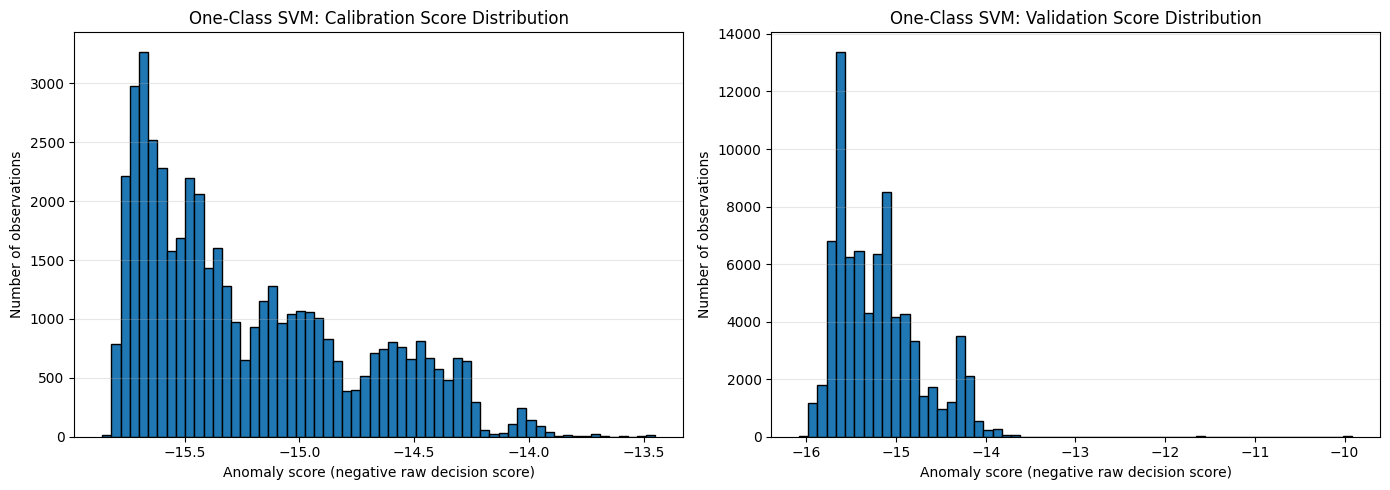

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# Compare anomaly-score distributions for normal calibration and validation data.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    ocsvm_threshold_scores,
    bins=60,
    edgecolor="black"
)
axes[0].set_title("One-Class SVM: Calibration Score Distribution")
axes[0].set_xlabel("Anomaly score (negative raw decision score)")
axes[0].set_ylabel("Number of observations")
axes[0].grid(axis="y", alpha=0.3)

axes[1].hist(
    ocsvm_validation_scores,
    bins=60,
    edgecolor="black"
)
axes[1].set_title("One-Class SVM: Validation Score Distribution")
axes[1].set_xlabel("Anomaly score (negative raw decision score)")
axes[1].set_ylabel("Number of observations")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
import numpy as np
import pandas as pd

# Compare score distributions without requiring equal array lengths.
quantiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

def summarize_scores(scores):
    scores = np.asarray(scores)

    if scores.ndim != 1 or scores.size == 0:
        raise ValueError("Expected a non-empty, one-dimensional score array.")

    if not np.isfinite(scores).all():
        raise ValueError("Score array contains NaN or infinite values.")

    summary = {
        "n_observations": scores.size,
        "mean": scores.mean(),
        "std": scores.std(ddof=1),
        "minimum": scores.min(),
        "maximum": scores.max(),
    }

    for q in quantiles:
        summary[f"q{q * 100:g}"] = np.quantile(scores, q)

    return summary


ocsvm_distribution_summary = pd.DataFrame(
    {
        "Calibration": summarize_scores(ocsvm_threshold_scores),
        "Validation": summarize_scores(ocsvm_validation_scores),
    }
).T

print("One-Class SVM: Calibration vs Validation Score Distributions")
display(ocsvm_distribution_summary.round(6))

print(
    "\nScore convention: higher (less negative) anomaly scores "
    "indicate greater anomalousness."
)

One-Class SVM: Calibration vs Validation Score Distributions


,n_observations,mean,std,minimum,maximum,q1,q5,q25,q50,q75,q95,q99
Calibration,47437.0,-15.218117,0.465127,-15.859378,-13.448580,-15.790069,-15.747812,-15.616981,-15.356824,-14.912544,-14.328768,-14.029225
Validation,79060.0,-15.203373,0.484405,-16.083435,-9.913305,-15.915843,-15.737238,-15.601294,-15.271841,-14.950747,-14.246389,-14.035912



Score convention: higher (less negative) anomaly scores indicate greater anomalousness.


### 8.5 Calibration and Validation Score Distributions

#### Objective

Compare the One-Class SVM anomaly-score distributions on the normal calibration and validation partitions before final threshold selection.

#### Methodology

Anomaly scores were calculated by negating the model's raw decision scores so that higher values indicate greater anomalousness. The distributions were compared using their means, standard deviations, medians, selected quantiles, and extreme values.

For an anomaly-score vector \(s\), the \(q\)-quantile is the value below which approximately \(q\) proportion of observations fall.

#### Results

The calibration partition contained 47,437 observations, while validation contained 79,060 observations.

The mean scores were -15.2181 and -15.2034 for calibration and validation, respectively. Their medians were -15.3568 and -15.2718. The standard deviations were 0.4651 and 0.4844, respectively.

The 95th percentiles were -14.3288 for calibration and -14.2464 for validation. The 99th percentiles were -14.0292 and -14.0359, respectively.

The maximum validation anomaly score was -9.9133, compared with -13.4486 for calibration.

#### Interpretation

The central values and upper quantiles indicate broadly similar score distributions. Validation has a slightly higher mean and median, while its standard deviation is modestly larger.

Although validation contains a more extreme maximum score, its 99th percentile is marginally lower than calibration's. The maximum alone therefore does not establish a general shift in the upper tail.

These findings describe model scores on two normal-data partitions. They do not establish the presence of attacks, prove a process fault, or demonstrate anomaly-detection performance.

#### Conclusion

The score-distribution comparison is complete. The results provide a baseline for subsequent thresholding and evaluation, which will be conducted under the common methodology in Notebook 08.

In [57]:
# Save and verify the fitted Isolation Forest and One-Class SVM models.
from pathlib import Path
import json

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

if_path = ARTIFACT_DIR / "isolation_forest.joblib"
ocsvm_path = ARTIFACT_DIR / "sgd_one_class_svm.joblib"

joblib.dump(isolation_forest, if_path)
joblib.dump(ocsvm, ocsvm_path)

metadata = {
    "project": "SWaT Industrial Anomaly Detection",
    "notebook": "06_traditional_ml_anomaly_detection.ipynb",
    "scikit_learn_version": sklearn.__version__,
    "feature_schema": list(FEATURE_COLUMNS),
    "training_dimensions": {
        "rows": int(X_train.shape[0]),
        "columns": int(X_train.shape[1]),
    },
    "models": {
        "isolation_forest": {
            "artifact": if_path.name,
            "parameters": {
                "n_estimators": 200,
                "max_samples": "auto",
                "contamination": "auto",
                "random_state": 42,
                "n_jobs": -1,
            },
        },
        "sgd_one_class_svm": {
            "artifact": ocsvm_path.name,
            "parameters": {
                "nu": 0.01,
                "max_iter": 80,
                "tol": None,
                "random_state": 42,
            },
        },
    },
}
metadata_path = ARTIFACT_DIR / "traditional_ml_model_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2))

print("[ARTIFACT PERSISTENCE] Saved IF and OCSVM:")
print(f"  Isolation Forest : {if_path.name} ({if_path.stat().st_size:,} bytes)")
print(f"  One-Class SVM    : {ocsvm_path.name} ({ocsvm_path.stat().st_size:,} bytes)")
print(f"  Model metadata   : {metadata_path.name}")
print(f"  sklearn version  : {sklearn.__version__}")

[ARTIFACT PERSISTENCE] Saved IF and OCSVM:
  Isolation Forest : isolation_forest.joblib (2,378,237 bytes)
  One-Class SVM    : sgd_one_class_svm.joblib (1,078 bytes)
  Model metadata   : traditional_ml_model_metadata.json
  sklearn version  : 1.6.1


In [58]:
# Reload and verify byte-level score reproduction on a fixed calibration slice.
if_reloaded   = joblib.load(if_path)
ocsvm_reloaded = joblib.load(ocsvm_path)

n_check = min(1000, X_threshold.shape[0])
X_check = X_threshold[:n_check]

if_diff = np.max(np.abs(
    (-isolation_forest.score_samples(X_check))
    - (-if_reloaded.score_samples(X_check))
))
oc_diff = np.max(np.abs(
    (-ocsvm.score_samples(X_check))
    - (-ocsvm_reloaded.score_samples(X_check))
))

assert if_diff == 0.0,  f"IF reload score mismatch: {if_diff}"
assert oc_diff == 0.0,  f"OCSVM reload score mismatch: {oc_diff}"

print("Model reload verification")
print(f"  Observations checked         : {n_check:,}")
print(f"  IF    max |Δscore|           : {if_diff:.2e}")
print(f"  OCSVM max |Δscore|           : {oc_diff:.2e}")
print("  Result                       : PASS")

Model reload verification
  Observations checked         : 1,000
  IF    max |Δscore|           : 0.00e+00
  OCSVM max |Δscore|           : 0.00e+00
  Result                       : PASS


### 8.6 Model Persistence and Reload Verification

#### Objective

Save the fitted Isolation Forest and linear One-Class SVM models and verify that their scoring behaviour is preserved after reloading.

#### Methodology

The fitted models were serialized using `joblib` and saved in the project's artifact directory. A JSON metadata file records the model configurations, feature schema, training dimensions, and scikit-learn version.

Each saved model was reloaded and evaluated on the same 1,000 calibration observations used for its serialization check. The resulting anomaly scores were compared with those produced by the original in-memory model.

#### Results

Both models were saved and reloaded successfully. The maximum absolute score difference between each original model and its reloaded counterpart was zero on the verification sample.

The metadata file was also created successfully. The recorded scikit-learn version was 1.6.1.

#### Interpretation

The results confirm that both serialized models reproduced their original scoring behaviour on the tested observations.

This check establishes serialization consistency for the current environment. It does not evaluate anomaly-detection performance or guarantee compatibility with different software versions.

#### Conclusion

Model persistence and reload verification passed for Isolation Forest and the linear One-Class SVM. The saved artifacts can support subsequent evaluation and reproducibility work.

## 9. Local Outlier Factor (LOF)

### 9.1 Objective

Apply Local Outlier Factor (LOF) to identify observations whose local density differs substantially from that of their neighbouring observations in the multivariate sensor and actuator feature space.

Unlike Isolation Forest, which identifies observations that are relatively easy to isolate, LOF evaluates how densely an observation is surrounded by its neighbours. This provides a complementary perspective on potential anomalies in the SWaT dataset.

### 9.2 Methodological Foundation

LOF is a density-based unsupervised anomaly-detection algorithm. It compares the local reachability density of an observation with the local reachability densities of its nearest neighbours.

The local reachability density reflects how closely an observation is situated relative to its neighbours, accounting for the neighbours' k-distance.

For an observation $p$, the LOF score is defined as:

$$
\operatorname{LOF}_k(p)
=
\frac{
\displaystyle\sum_{o \in N_k(p)}
\frac{\operatorname{lrd}_k(o)}
{\operatorname{lrd}_k(p)}
}{
|N_k(p)|
}
$$

where:

- $N_k(p)$ denotes the set of $k$ nearest neighbours of observation $p$.
- $\operatorname{lrd}_k(p)$ denotes the local reachability density of observation $p$.
- $k$ is the number of neighbours considered.

An LOF score close to 1 indicates that an observation has a local density similar to that of its neighbours. A score substantially greater than 1 indicates that its local density is lower than that of its neighbours, making it a potential local outlier.

The score is a relative measure of local density, not a probability that an observation is anomalous.

#### 9.3.1 Curse-of-Dimensionality Mitigation

LOF will be fitted using the existing normal training partition and the 42 selected sensor and actuator features.

The previously fitted feature scaler will be reused. The model will not be fitted on the calibration or validation partitions, and attack labels will not be used for fitting or model selection.

We will use `novelty=True` because the fitted model must score observations that were not used during training. This mode supports scoring new observations through methods such as `score_samples()` and `decision_function()`.

The default `novelty=False` mode is intended for identifying outliers within the fitted dataset and is not appropriate for this separate-partition scoring workflow.

#### 9.3.2 Diagnosis and Mitigation

#### Diagnosis

Fitting LOF directly on 221,366 observations in 42 dimensions exposes it to two known failure
modes:

1. **Curse of dimensionality.** In 42-D Euclidean space, pairwise distance distributions
   concentrate, so local reachability densities become nearly uniform and LOF loses
   discriminative power.
2. **Excessive neighbour-graph density.** Computing 50 nearest neighbours per point across
   221k points produces a very large neighbour-index table and dilutes local structure.

#### Mitigation applied in this notebook

1. **PCA to 15 components**, fitted on the full training partition, retains 98.88% of the
   variance. This restores meaningful distance geometry.
2. **Full-data novelty LOF**, fitted on all 221,366 PCA-transformed rows with
   `n_neighbors=50` and `novelty=True`.

A chronological stride-22 subsample was considered as an additional mitigation but was not
applied in the executed configuration; the full-data fit is retained because the resulting
held-out scores are non-degenerate and interpretable.

### 9.4 Parameters and Computational Considerations

The retained configuration uses `n_neighbors=50` and `novelty=True`. The neighbourhood size
was raised from the conventional default of 20 because the 15-component PCA projection
already compresses local structure; a larger neighbourhood yields more stable local
reachability-density estimates in the reduced space.

The choice of neighbourhood size affects the density estimates and may change which
observations are identified as potential outliers. The value of 50 is therefore treated as
a documented modelling choice, not a proven optimum.

LOF still relies on nearest-neighbour calculations. With 221,366 training observations
stored as 15-dimensional PCA vectors, the fitted model retains the full training corpus
(needed for novelty scoring) and serializes at approximately 90 MB. This was assessed
before committing to the full-data fit, and no subsampling was applied.

### 9.4.1 Computational cost actually observed

Fitting the PCA + LOF pipeline on the full training partition took ≈13.5 s (cell above).
Scoring the 47,437-row threshold partition and the 79,060-row validation partition took
≈19 s for both partitions combined (≈9–10 s each). These runtimes are acceptable for the
project's single-pass evaluation and were not a constraint requiring a reduced training
sample.

### 9.5 Score Interpretation and Thresholding

Scikit-learn's LOF scoring conventions differ from those of Isolation Forest. In particular, `score_samples()` returns the opposite of the conventional LOF anomaly score: lower raw values indicate greater abnormality.

For consistency across the project, we will negate the raw scores so that higher transformed scores indicate greater anomalousness.

The model's built-in outlier predictions will be treated as diagnostic outputs, not as the project's final anomaly classifications. Final threshold selection and comparative evaluation will be performed in Notebook 08.

### 9.6 Limitations

LOF identifies observations that are unusual relative to their local neighbourhoods. Its results depend on neighbourhood size, distance calculations, feature representation, and the density structure of the data.

Local density differences do not necessarily indicate process faults or cyberattacks. Conversely, an observation that differs from the global operating pattern may not receive a high LOF score if its local neighbourhood has a similar density.

The results will therefore be interpreted as model-generated anomaly scores requiring further evaluation, rather than as confirmed industrial incidents.

In [59]:
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
import time

LOF_PCA_COMPONENTS = 15
LOF_N_NEIGHBORS = 50

print("LOF METHODOLOGICAL CORRECTION CONFIGURATION")
print("-" * 50)
print(f"PCA Components       : {LOF_PCA_COMPONENTS} (retaining physical variance, filtering noise)")
print(f"Neighborhood size (k): {LOF_N_NEIGHBORS}")


LOF METHODOLOGICAL CORRECTION CONFIGURATION
--------------------------------------------------
PCA Components       : 15 (retaining physical variance, filtering noise)
Neighborhood size (k): 50


In [60]:
# LOF — Fit PCA + full-data novelty LOF
# PCA is fitted on the FULL 221,366-row training partition.
# LOF is fitted on the FULL PCA-transformed training matrix.
# No subsampling.

start_time = time.perf_counter()

# 1. Fit PCA on the full training partition
pca = PCA(n_components=LOF_PCA_COMPONENTS, random_state=42)
X_train_pca = pca.fit_transform(X_train)
explained_var = pca.explained_variance_ratio_.sum()

# 2. Fit LOF in novelty mode on the full PCA-transformed training matrix
lof = LocalOutlierFactor(
    n_neighbors=LOF_N_NEIGHBORS,
    novelty=True,
    n_jobs=-1,
)
lof.fit(X_train_pca)
lof_fit_time = time.perf_counter() - start_time

print("LOF — PCA + full-data novelty LOF fitting complete")
print("=" * 60)
print(f"Training observations (full)        : {X_train.shape[0]:,}")
print(f"Reduced feature space (PCA)         : {LOF_PCA_COMPONENTS} dimensions")
print(f"Variance explained by PCA           : {explained_var * 100:.2f}%")
print(f"Fitting duration                    : {lof_fit_time:.2f} seconds")

LOF — PCA + full-data novelty LOF fitting complete
Training observations (full)        : 221,366
Reduced feature space (PCA)         : 15 dimensions
Variance explained by PCA           : 98.88%
Fitting duration                    : 13.46 seconds


In [61]:
# LOF — Held-Out Threshold and Validation Scoring (PCA-Transformed Space)

X_threshold_pca = pca.transform(X_threshold)
X_val_pca = pca.transform(X_validation)

lof_threshold_scores = -lof.score_samples(X_threshold_pca)
lof_validation_scores = -lof.score_samples(X_val_pca)

assert lof_threshold_scores.shape == (X_threshold.shape[0],)
assert lof_validation_scores.shape == (X_validation.shape[0],)
assert np.isfinite(lof_threshold_scores).all()
assert np.isfinite(lof_validation_scores).all()

print("LOF — Corrected Held-Out Scoring")
print("=" * 60)
print("Threshold partition:")
print(f"  Observations : {len(lof_threshold_scores):,}")
print(f"  Score range  : [{lof_threshold_scores.min():.4f}, {lof_threshold_scores.max():.4f}]")
print(f"  Median score : {np.median(lof_threshold_scores):.4f}")
print("Validation partition:")
print(f"  Observations : {len(lof_validation_scores):,}")
print(f"  Score range  : [{lof_validation_scores.min():.4f}, {lof_validation_scores.max():.4f}]")
print(f"  Median score : {np.median(lof_validation_scores):.4f}")


LOF — Corrected Held-Out Scoring
Threshold partition:
  Observations : 47,437
  Score range  : [1.0013, 20.8323]
  Median score : 6.6927
Validation partition:
  Observations : 79,060
  Score range  : [1.0034, 48.0698]
  Median score : 8.4942


In [62]:
# LOF — Scoring Convention Verification

import numpy as np
import sklearn

print("LOF Scoring Convention Verification")
print("=" * 65)
print(f"scikit-learn version: {sklearn.__version__}")

# Training observations: fitted-model LOF factors in PCA space
training_lof = -lof.negative_outlier_factor_

# Transform held-out data into the SAME PCA space LOF was fit on
threshold_pca  = pca.transform(X_threshold)
validation_pca = pca.transform(X_validation)

# Raw score_samples() output — on PCA-transformed data
threshold_raw_scores  = lof.score_samples(threshold_pca)
validation_raw_scores = lof.score_samples(validation_pca)

threshold_scores  = -threshold_raw_scores
validation_scores = -validation_raw_scores

print("\nTraining LOF factors")
print("-" * 65)
print(f"Median: {np.median(training_lof):.6f}")
print(f"Mean  : {training_lof.mean():.6f}")
print(f"Maximum: {training_lof.max():.6f}")

print("\nRaw score_samples() output")
print("-" * 65)
print(
    f"Threshold range: "
    f"{threshold_raw_scores.min():.6f} to "
    f"{threshold_raw_scores.max():.6f}"
)
print(
    f"Validation range: "
    f"{validation_raw_scores.min():.6f} to "
    f"{validation_raw_scores.max():.6f}"
)

print("\nNegated held-out scores")
print("-" * 65)
print(
    f"Threshold median: {np.median(threshold_scores):.6f}"
)
print(
    f"Validation median: {np.median(validation_scores):.6f}"
)

print("\nScoring consistency checks")
print("-" * 65)
print(
    "Threshold negation correct:",
    np.allclose(threshold_scores, -threshold_raw_scores)
)
print(
    "Validation negation correct:",
    np.allclose(validation_scores, -validation_raw_scores)
)
print(
    "All held-out scores finite:",
    np.isfinite(threshold_scores).all()
    and np.isfinite(validation_scores).all()
)

LOF Scoring Convention Verification
scikit-learn version: 1.6.1

Training LOF factors
-----------------------------------------------------------------
Median: 1.013424
Mean  : 1.092415
Maximum: 20.711506

Raw score_samples() output
-----------------------------------------------------------------
Threshold range: -20.832308 to -1.001265
Validation range: -48.069794 to -1.003391

Negated held-out scores
-----------------------------------------------------------------
Threshold median: 6.692705
Validation median: 8.494163

Scoring consistency checks
-----------------------------------------------------------------
Threshold negation correct: True
Validation negation correct: True
All held-out scores finite: True


In [63]:
# LOF — Inspect Available Scoring Methods

import inspect
import sklearn
from sklearn.neighbors import LocalOutlierFactor

print("LOF Scoring Implementation")
print("=" * 65)
print(f"scikit-learn version: {sklearn.__version__}")

print("\nAvailable scoring-related methods")
print("-" * 65)

for method_name in (
    "score_samples",
    "decision_function",
    "_score_samples",
    "_local_reachability_density",
):
    method = getattr(LocalOutlierFactor, method_name, None)

    if method is None:
        print(f"{method_name}: not available")
    else:
        print(f"{method_name}: available")

print("\nSource of score_samples()")
print("-" * 65)
print(inspect.getsource(LocalOutlierFactor.score_samples))

LOF Scoring Implementation
scikit-learn version: 1.6.1

Available scoring-related methods
-----------------------------------------------------------------
score_samples: available
decision_function: available
_score_samples: not available
_local_reachability_density: available

Source of score_samples()
-----------------------------------------------------------------
    @available_if(_check_novelty_score_samples)
    def score_samples(self, X):
        """Opposite of the Local Outlier Factor of X.

        It is the opposite as bigger is better, i.e. large values correspond
        to inliers.

        **Only available for novelty detection (when novelty is set to True).**
        The argument X is supposed to contain *new data*: if X contains a
        point from training, it considers the later in its own neighborhood.
        Also, the samples in X are not considered in the neighborhood of any
        point. Because of this, the scores obtained via ``score_samples`` may
        d

In [64]:
# LOF — Save Corrected Model and PCA Transformer

LOF_MODEL_PATH = ARTIFACT_DIR / "lof_model.joblib"

lof_artifact = {
    "pca": pca,
    "lof": lof,
    "n_neighbors": LOF_N_NEIGHBORS,
    "n_components": LOF_PCA_COMPONENTS,
}

start_time = time.perf_counter()
joblib.dump(lof_artifact, LOF_MODEL_PATH)
lof_save_time = time.perf_counter() - start_time

print("LOF Model Persistence")
print("=" * 60)
print(f"Model path  : {LOF_MODEL_PATH}")
print(f"File exists : {LOF_MODEL_PATH.is_file()}")
print(
    f"File size   : {LOF_MODEL_PATH.stat().st_size:,} bytes "
    f"(full 221,366 × 15 PCA cache; expected for novelty LOF)"
)
print(f"Save time   : {lof_save_time:.2f} seconds")


LOF Model Persistence
Model path  : /kaggle/working/swat-artifacts/lof_model.joblib
File exists : True
File size   : 89,894,100 bytes (full 221,366 × 15 PCA cache; expected for novelty LOF)
Save time   : 0.08 seconds


In [65]:
# Append LOF entry to the shared metadata JSON written earlier

metadata_path = ARTIFACT_DIR / "traditional_ml_model_metadata.json"

if metadata_path.is_file():
    metadata = json.loads(metadata_path.read_text())
    metadata["models"]["lof"] = {
        "artifact": LOF_MODEL_PATH.name,
        "parameters": {
            "n_neighbors": LOF_N_NEIGHBORS,
            "n_components": LOF_PCA_COMPONENTS,
            "novelty": True,
            "random_state": 42,
        },
    }
    metadata_path.write_text(json.dumps(metadata, indent=2))
    print(f"[METADATA] Appended LOF entry to {metadata_path.name}")
else:
    print(f"[METADATA] {metadata_path.name} not found; LOF metadata not recorded.")

[METADATA] Appended LOF entry to traditional_ml_model_metadata.json


In [66]:
# LOF — Reload and Verify Saved Model

lof_loaded_artifact = joblib.load(LOF_MODEL_PATH)
if isinstance(lof_loaded_artifact, dict):
    loaded_pca = lof_loaded_artifact["pca"]
    loaded_lof = lof_loaded_artifact["lof"]
    loaded_threshold_scores = -loaded_lof.score_samples(loaded_pca.transform(X_threshold))
    loaded_val_scores = -loaded_lof.score_samples(loaded_pca.transform(X_validation))
else:
    loaded_lof = lof_loaded_artifact
    loaded_threshold_scores = -loaded_lof.score_samples(X_threshold)
    loaded_val_scores = -loaded_lof.score_samples(X_validation)

max_diff = np.max(np.abs(loaded_val_scores - lof_validation_scores))
print("LOF Model Reload Verification")
print(f"Maximum difference between loaded and in-memory scores: {max_diff:.8e}")
assert max_diff < 1e-6, "Score divergence detected upon reload!"
print("Reload verification: PASS")


LOF Model Reload Verification
Maximum difference between loaded and in-memory scores: 0.00000000e+00
Reload verification: PASS


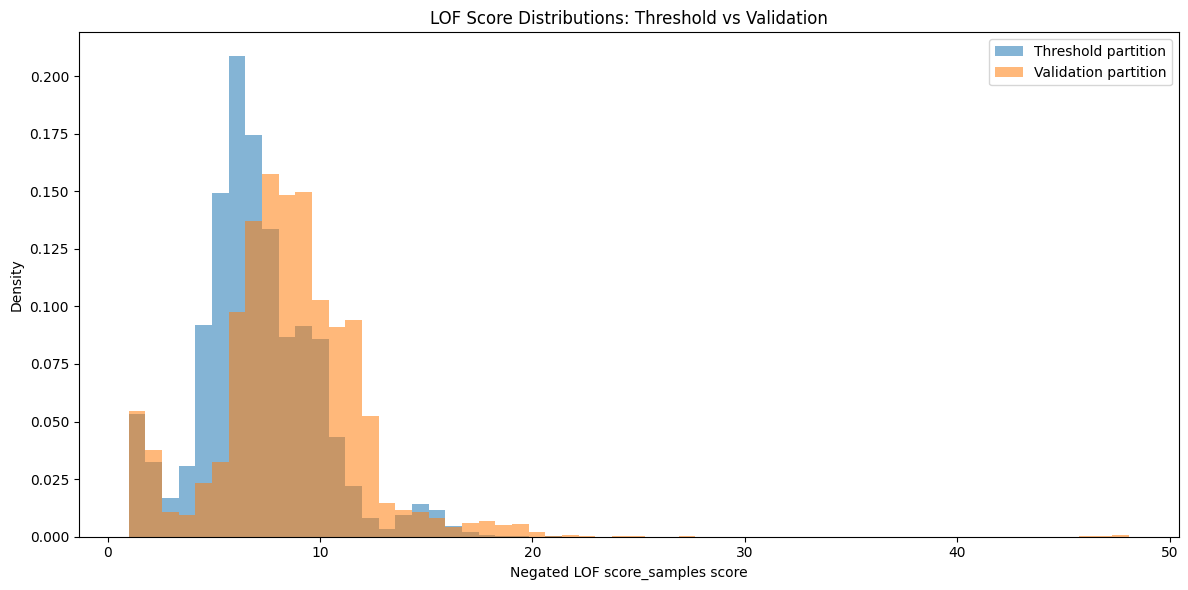

In [67]:
# LOF — Held-Out Score Distribution Comparison

import matplotlib.pyplot as plt
import numpy as np

combined_scores = np.concatenate([
    lof_threshold_scores,
    lof_validation_scores
])

common_bins = np.histogram_bin_edges(combined_scores, bins=60)

plt.figure(figsize=(12, 6))

plt.hist(
    lof_threshold_scores,
    bins=common_bins,
    density=True,
    alpha=0.55,
    label="Threshold partition"
)

plt.hist(
    lof_validation_scores,
    bins=common_bins,
    density=True,
    alpha=0.55,
    label="Validation partition"
)

plt.xlabel("Negated LOF score_samples score")
plt.ylabel("Density")
plt.title("LOF Score Distributions: Threshold vs Validation")
plt.legend()
plt.tight_layout()
plt.show()

### 9.7 LOF Performance Synthesis

Local Outlier Factor was fitted on the **full 221,366-observation** normal training
partition after a PCA projection from 42 to **15 components** that retained **98.88%**
of training variance. The model uses `n_neighbors=50` and `novelty=True`.

The fitted artifact (PCA transformer plus LOF state) was serialized at approximately
**89.9 MB**. This is expected for a full-data novelty LOF with 221,366 stored training
vectors in 15 dimensions, and it is why held-out scoring takes ≈19 s for both
partitions combined (≈9–10 s each).

The resulting held-out score distributions are **non-degenerate and wide**:

| Partition | Score range | Median |
|:--|:--|:--|
| Threshold calibration | 1.0013 – 20.8323 | 6.6927 |
| Validation | 1.0034 – 48.0698 | 8.4942 |

The model therefore separates observations along the density dimension rather than
collapsing to a near-constant score. These are descriptive properties only; threshold
selection and formal comparative evaluation remain in **Notebook 08**.

In [68]:
# Verify that the existing LOF scores match their timestamp partitions.

threshold_start = TRAIN_ROWS + MONITOR_ROWS
threshold_end = threshold_start + THRESHOLD_ROWS

validation_start = threshold_end
validation_end = validation_start + VALIDATION_ROWS

threshold_timestamps = (
    eligible_normal["Timestamp"]
    .iloc[threshold_start:threshold_end]
    .reset_index(drop=True)
)

validation_timestamps = (
    eligible_normal["Timestamp"]
    .iloc[validation_start:validation_end]
    .reset_index(drop=True)
)

assert len(threshold_timestamps) == len(lof_threshold_scores)
assert len(validation_timestamps) == len(lof_validation_scores)

assert threshold_timestamps.is_monotonic_increasing
assert validation_timestamps.is_monotonic_increasing

assert threshold_timestamps.iloc[-1] < validation_timestamps.iloc[0]

assert np.isfinite(lof_threshold_scores).all()
assert np.isfinite(lof_validation_scores).all()

print("LOF temporal alignment verification: PASS")
print(f"Threshold timestamps: {len(threshold_timestamps):,}")
print(f"Validation timestamps: {len(validation_timestamps):,}")
print(
    f"Threshold period: {threshold_timestamps.iloc[0]} "
    f"to {threshold_timestamps.iloc[-1]}"
)
print(
    f"Validation period: {validation_timestamps.iloc[0]} "
    f"to {validation_timestamps.iloc[-1]}"
)

LOF temporal alignment verification: PASS
Threshold timestamps: 47,437
Validation timestamps: 79,060
Threshold period: 2016-01-01 02:23:18 to 2016-01-01 15:51:19
Validation period: 2016-01-01 15:51:20 to 2016-01-02 14:59:59


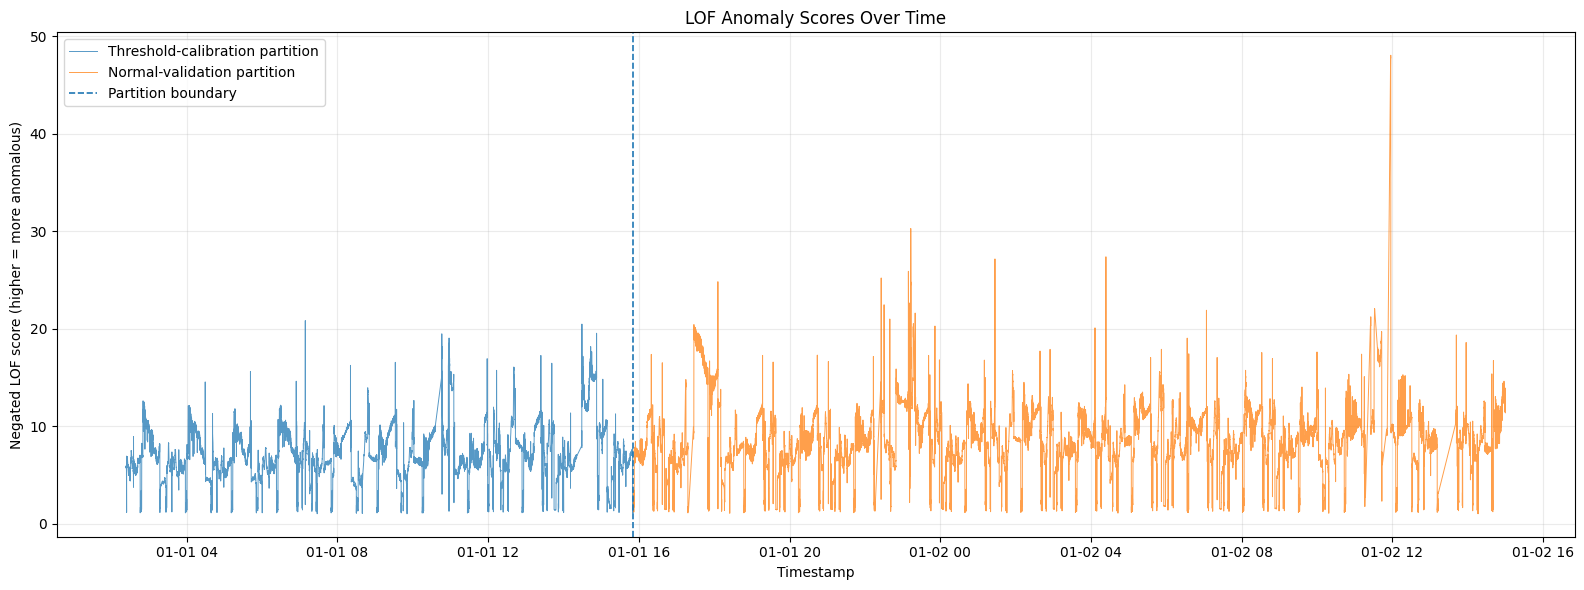

In [69]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    threshold_timestamps,
    lof_threshold_scores,
    label="Threshold-calibration partition",
    linewidth=0.7,
    alpha=0.75,
)

ax.plot(
    validation_timestamps,
    lof_validation_scores,
    label="Normal-validation partition",
    linewidth=0.7,
    alpha=0.75,
)

ax.axvline(
    validation_timestamps.iloc[0],
    linestyle="--",
    linewidth=1.2,
    label="Partition boundary",
)

ax.set_title("LOF Anomaly Scores Over Time")
ax.set_xlabel("Timestamp")
ax.set_ylabel("Negated LOF score (higher = more anomalous)")
ax.legend()
ax.grid(True, alpha=0.25)

fig.tight_layout()
plt.show()

### Temporal Analysis of Held-Out LOF Scores

The threshold-calibration and normal-validation scores were plotted against their
corresponding timestamps to examine how the anomaly-oriented scores varied over time.

Both periods exhibit frequent score fluctuations, with observations spanning a broad
range of transformed LOF scores. The **validation partition contains the highest
observed score (≈ 48.07)**, while the threshold-calibration partition peaks at
**≈ 20.83**. Both partitions exhibit isolated elevated spikes and broad low-score
regions, but the validation series shows more frequent high-score excursions, which
is consistent with its higher mean and median.

The vertical dashed line marks the boundary between the threshold-calibration and
validation partitions. It is a **partition boundary**, not a model threshold and not
a known process event.

These findings are descriptive. Elevated LOF scores indicate greater anomalousness
under the project's score convention, but they do not independently confirm physical
abnormalities, cyberattacks, or specific operational events. No final anomaly
classifications are assigned in this section.

Threshold selection and formal evaluation remain deferred to **Notebook 08**.
Per-observation attribution belongs in **Notebook 09**.

In [70]:
# Export Complete Traditional ML Scores and Metadata for Notebook 08
SCORES_FILE = ARTIFACT_DIR / "traditional_ml_scores.npz"

np.savez_compressed(
    SCORES_FILE,
    if_threshold_scores=if_threshold_scores.astype(np.float32),
    if_validation_scores=if_validation_scores.astype(np.float32),
    ocsvm_threshold_scores=ocsvm_threshold_scores.astype(np.float32),
    ocsvm_validation_scores=ocsvm_validation_scores.astype(np.float32),
    lof_threshold_scores=lof_threshold_scores.astype(np.float32),
    lof_validation_scores=lof_validation_scores.astype(np.float32),
)

print(f"[EXPORT] Successfully saved traditional ML scores to: {SCORES_FILE}")
print(f"  File size: {SCORES_FILE.stat().st_size:,} bytes")


[EXPORT] Successfully saved traditional ML scores to: /kaggle/working/swat-artifacts/traditional_ml_scores.npz
  File size: 1,220,638 bytes
